# Agenda

1) Data extraction/Pre-processing
2) EDA
3) Feature engineering
4) Model training and evaluation
5) Model selection

# Import Libraries (common)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data

In [2]:
"""Load data from files"""
import glob as gl
import pandas as pd
import pathlib as pth


def load_file(path: str, load_all: bool = False, filter: str = None, sep: str = None, header: int = 0) -> pd.DataFrame:
    if pth.Path(path).is_file():
        if path.endswith(".csv"):
            dfs = pd.read_csv(path, header=header)
        elif path.endswith(".txt"):
            dfs = pd.read_csv(path, sep=sep, header=header)
        elif path.endswith(".xlsx"):
            dfs = pd.read_excel(path, header=header)
    elif pth.Path(path).is_dir() and load_all:
        df_list = []
        files = gl.glob(f"{path}/*")
        if filter:
            files = [i for i in files if filter in i]
        print("files to be loaded:", files)
        for file in files:
            if file.endswith(".csv"):
                df = pd.read_csv(file, low_memory=False, header=header)
                df_list.append(df)
            elif file.endswith(".txt"):
                df = pd.read_csv(file, sep=sep, header=header)
                df_list.append(df)
            elif file.endswith(".xlsx"):
                df = pd.read_excel(file, header=header)
                df_list.append(df)                
        dfs = pd.concat(df_list)
        dfs.reset_index(drop=True, inplace=True)
    elif pth.Path(path).is_dir() and not load_all:
        raise ValueError("load_all should be True")
    else:
        raise ValueError("error")

    return dfs

In [3]:
# Get contents from csv file
train_df = load_file(path="data/train.csv", load_all=False, header=0)
# test_df = load_file(path="data/test.csv", load_all=False, header=0)  # no labels; we will not use
store_df = load_file(path="data/stores.csv", load_all=False, header=0)
feature_df = load_file(path="data/features.csv", load_all=False, header=0)
us_holiday_df = load_file(path="data/US Holiday Dates (2004-2021).csv", load_all=False, header=0)

In [4]:
# Display first 5 rows of each df
print("train_df")
print(train_df.head())
print()
# print("test_df")
# print(test_df.head())
# print()
print("store")
print(store_df.head())
print()
print("features")
print(feature_df.head())
print()
print("holiday")
print(us_holiday_df.head())

train_df
   Store  Dept        Date  Weekly_Sales  IsHoliday
0      1     1  2010-02-05      24924.50      False
1      1     1  2010-02-12      46039.49       True
2      1     1  2010-02-19      41595.55      False
3      1     1  2010-02-26      19403.54      False
4      1     1  2010-03-05      21827.90      False

store
   Store Type    Size
0      1    A  151315
1      2    A  202307
2      3    B   37392
3      4    A  205863
4      5    B   34875

features
   Store        Date  Temperature  Fuel_Price  MarkDown1  MarkDown2  \
0      1  2010-02-05        42.31       2.572        NaN        NaN   
1      1  2010-02-12        38.51       2.548        NaN        NaN   
2      1  2010-02-19        39.93       2.514        NaN        NaN   
3      1  2010-02-26        46.63       2.561        NaN        NaN   
4      1  2010-03-05        46.50       2.625        NaN        NaN   

   MarkDown3  MarkDown4  MarkDown5         CPI  Unemployment  IsHoliday  
0        NaN        NaN      

In [5]:
# Check min and max date for data period
print(train_df["Date"].min(), train_df["Date"].max())
# Length of data
print(len(train_df))

2010-02-05 2012-10-26
421570


In [6]:
# display irregular sales (some interval between weeks and negative values)
train_df[(train_df["Store"]==45) & (train_df["Dept"]==47)]

,Store,Dept,Date,Weekly_Sales,IsHoliday
417801,45,47,2010-02-26,-1750.00,False
417802,45,47,2010-05-28,100.00,False
417803,45,47,2010-09-24,70.00,False
417804,45,47,2010-12-24,124.00,False
417805,45,47,2011-02-11,0.00,True
417806,45,47,2011-03-25,20.00,False
417807,45,47,2011-04-08,20.00,False
417808,45,47,2011-05-13,20.00,False
417809,45,47,2011-11-18,-24.00,False
417810,45,47,2011-12-23,95.00,False


## Pre-processing

### Impute Weekly_Sales by zero

In [7]:
# Get unique store-product combinations for imputation
combinations = train_df[["Store", "Dept"]].drop_duplicates()
combinations

# Shallow copy
process_df = train_df.copy()
# Date column > Date type
process_df["Date"] = pd.to_datetime(process_df["Date"])
# Set date column as index
process_df.set_index("Date", inplace=True)
# Sorting by index (date) for filtering on later process
process_df.sort_index(inplace=True)

p_df_resampled_list = []

# Imputation no sales bewteen certian week by zero 
for _, row in combinations.iterrows():
    store_id = row["Store"]
    dept = row["Dept"]

    # Filter df for specific store and dept
    p_df = process_df[(process_df["Store"] == store_id) & (process_df["Dept"] == dept)]
        
    # Resample to a weekly frequency (keeping Friday) and fill missing values with zero
    p_df_resampled = p_df.resample('W-FRI').asfreq()

    # Fill previous value for store, dept and 0 for weekly sales
    p_df_resampled["Store"] = p_df_resampled["Store"].ffill()
    p_df_resampled["Dept"] = p_df_resampled["Dept"].ffill()
    p_df_resampled["Weekly_Sales"] = p_df_resampled["Weekly_Sales"].fillna(0)
        
    # Append the preprocessed group to the list
    p_df_resampled_list.append(p_df_resampled)

# Concatenate all preprocessed groups into a single DataFrame
processed_data = pd.concat(p_df_resampled_list)
# Reset index for later process
processed_data = processed_data.reset_index()

# Change data time
processed_data["Store"] = processed_data["Store"].astype(int)
processed_data["Dept"] = processed_data["Dept"].astype(int)
processed_data["Date"] = processed_data["Date"].dt.strftime("%Y-%m-%d")

# Check whether total sales changed due to the process or not.
assert abs(processed_data["Weekly_Sales"].sum()-train_df["Weekly_Sales"].sum()) < 0.01

# Store processed data as train df
train_df = processed_data
train_df

,Date,Store,Dept,Weekly_Sales,IsHoliday
0,2010-02-05,1,1,24924.50,False
1,2010-02-12,1,1,46039.49,True
2,2010-02-19,1,1,41595.55,False
3,2010-02-26,1,1,19403.54,False
4,2010-03-05,1,1,21827.90,False
...,...,...,...,...,...
449232,2012-09-28,45,98,508.37,False
449233,2012-10-05,45,98,628.10,False
449234,2012-10-12,45,98,1061.02,False
449235,2012-10-19,45,98,760.01,False


### Remove less than 2month data 

In [8]:
# deine date to check continuous last 8 weeks; we will predict last 4 weeks so would like to avoid any missing sales during those periods.
max_date = max(process_df.index)
cut_date = max_date - pd.Timedelta(weeks=7, days=1)
print(max_date, cut_date)

count_train_df = process_df[cut_date:].reset_index()
count_train_df = count_train_df.groupby(["Store", "Dept"])["Date"].count().reset_index()
count_train_df = count_train_df[count_train_df["Date"]>=8]
count_train_df = count_train_df[["Store", "Dept"]]

train_df = train_df.merge(count_train_df, on=["Store", "Dept"], how="inner")
train_df

2012-10-26 00:00:00 2012-09-06 00:00:00


,Date,Store,Dept,Weekly_Sales,IsHoliday
0,2010-02-05,1,1,24924.50,False
1,2010-02-12,1,1,46039.49,True
2,2010-02-19,1,1,41595.55,False
3,2010-02-26,1,1,19403.54,False
4,2010-03-05,1,1,21827.90,False
...,...,...,...,...,...
406814,2012-09-28,45,98,508.37,False
406815,2012-10-05,45,98,628.10,False
406816,2012-10-12,45,98,1061.02,False
406817,2012-10-19,45,98,760.01,False


In [9]:
# Merge store info and features into sales data
# train
print("train data")
print("row count before merging:", train_df.shape[0])
merged_train_df = pd.merge(train_df, store_df, on='Store', how='left')
print("row count after merging store master:", merged_train_df.shape[0])
merged_train_df = pd.merge(merged_train_df, feature_df.drop(columns="IsHoliday"), on=['Store', 'Date'], how='left')
print("row count after merging features:", merged_train_df.shape[0])
# print(merged_train_df.head())

# # test
# print("test data")
# print("row count before merging:", test_df.shape[0])
# merged_test_df = pd.merge(test_df, store_df, on='Store', how='left')
# print("row count after merging store master:", merged_test_df.shape[0])
# merged_test_df = pd.merge(merged_test_df, feature_df.drop(columns="IsHoliday"), on=['Store', 'Date'], how='left')
# print("row count after merging features:", merged_test_df.shape[0])
# # print(merged_test_df.head())


train data
row count before merging: 406819
row count after merging store master: 406819
row count after merging features: 406819


In [10]:
# Fix date to be Friday for holiday data; weekly sales is stored with Friday
def to_previous_friday(df: pd.DataFrame, date_col: str, ) -> pd.DataFrame:
    if not isinstance(df[date_col][0], pd.Timestamp):
        df[date_col] = pd.to_datetime(df[date_col])

    df[f"{date_col}"] = df[date_col].apply(lambda x: x - pd.DateOffset(days=((x.weekday() + (7-4)) % 7)))
    df = df.drop_duplicates(subset=[date_col])

    return df

us_holiday_df = to_previous_friday(us_holiday_df, "Date")
us_holiday_df["IsHoliday"] = us_holiday_df["Holiday"]
us_holiday_df = us_holiday_df[["Date", "IsHoliday"]]
us_holiday_df

,Date,IsHoliday
0,2004-07-02,4th of July
1,2005-07-01,4th of July
2,2006-06-30,4th of July
3,2007-06-29,4th of July
4,2008-07-04,4th of July
...,...,...
333,2012-04-06,Western Easter
335,2009-04-10,Western Easter
336,2020-04-10,Western Easter
337,2006-04-14,Western Easter


In [11]:
import pandas as pd

def add_more_date_feature(df: pd.DataFrame, date_col: str) -> pd.DataFrame:
    if not isinstance(df[date_col][0], pd.Timestamp):
        df[date_col] = pd.to_datetime(df[date_col])
    
    # Extract year, quarter, month and week from date
    df["year"] = df[date_col].apply(lambda x: x.year)
    df["quarter"] = df[date_col].apply(lambda x: x.quarter)
    df["month"] = df[date_col].apply(lambda x: x.month)
    df["week"] = df[date_col].apply(lambda x: x.week)

    return df

In [12]:
# Add year, quarter, month, day columns
merged_train_df = add_more_date_feature(merged_train_df, "Date")
# merged_test_df = add_more_date_feature(merged_test_df, "Date")

print("train data")
print("row count before merging:", merged_train_df.shape[0])
merged_train_df = pd.merge(merged_train_df.drop(columns="IsHoliday"), us_holiday_df, on="Date", how="left")
print("row count after merging:", merged_train_df.shape[0])
# print("test data")
# print("row count before merging:", merged_test_df.shape[0])
# merged_test_df = pd.merge(merged_test_df.drop(columns="IsHoliday"), us_holiday_df, on="Date", how="left")
# print("row count after merging:", merged_test_df.shape[0])

print(merged_train_df.head())
# print(merged_test_df.head())


train data
row count before merging: 406819
row count after merging: 406819
        Date  Store  Dept  Weekly_Sales Type    Size  Temperature  Fuel_Price  \
0 2010-02-05      1     1      24924.50    A  151315        42.31       2.572   
1 2010-02-12      1     1      46039.49    A  151315        38.51       2.548   
2 2010-02-19      1     1      41595.55    A  151315        39.93       2.514   
3 2010-02-26      1     1      19403.54    A  151315        46.63       2.561   
4 2010-03-05      1     1      21827.90    A  151315        46.50       2.625   

   MarkDown1  MarkDown2  MarkDown3  MarkDown4  MarkDown5         CPI  \
0        NaN        NaN        NaN        NaN        NaN  211.096358   
1        NaN        NaN        NaN        NaN        NaN  211.242170   
2        NaN        NaN        NaN        NaN        NaN  211.289143   
3        NaN        NaN        NaN        NaN        NaN  211.319643   
4        NaN        NaN        NaN        NaN        NaN  211.350143   

   U

# EDA

## General EDA

In [13]:
"""EDA modules"""
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


class EDA:
    """Class for General EDA.

    variables
    ----------
    df: pd.DataFrame
    target_col: str
        Target column on dataframe (only one column)
        - This column would be defined if you want to explicitly compare to other features
    ----------
    """
    def __init__(self, df: pd.DataFrame, target_col: str = None) -> None:
        """Initialize variables and define columns."""
        self._df = df
        self._tgt_col = target_col
        self._num_cols = df.select_dtypes(include="number").columns
        self._cat_cols = df.select_dtypes(include=["object", "category"]).columns
        print("Numerical columns")
        print(self._num_cols)
        print("--------")
        print("Categorical columns")
        print(self._cat_cols)
        print("--------")
        print("Target column")

    def describe_df(self) -> None:
        """Describe dataframe; info, nunique, null ratio & describe."""
        print("Overall")
        print(self._df.info())
        print("--------")
        print("Unique value count")
        print(self._df.nunique())
        print("--------")
        print("Null value rate")
        print(self._df.isnull().sum()/len(self._df)*100)
        print("--------")
        print("Describe numerical columns")
        print(self._df.describe())
        print("--------")
        if len(self._cat_cols) > 0:
            print("Describe categorical columns")
            print(self._df.describe(include="object"))
            print("--------")

    def dist_plot(self) -> None:
        """Distribution plots: histgram, boxplot & violin plot.

        If target column defined, then plots will be generated except the target column.
        """
        if self._tgt_col:
            for col in [x for x in self._num_cols if x != self._tgt_col]:
                f, ax = plt.subplots(1,3,figsize=(12,3))
                sns.histplot(self._df, x=col, ax=ax[0], kde=True, bins=20, stat="percent", hue=self._tgt_col)
                sns.boxplot(self._df, x=col, hue=self._tgt_col, ax=ax[1])
                sns.violinplot(self._df, x=col, hue=self._tgt_col, ax=ax[2], alpha=0.3)
                plt.legend()
                plt.show()

        else:
            for col in self._num_cols:
                f, ax = plt.subplots(1,3,figsize=(12,3))
                sns.histplot(self._df, x=col, ax=ax[0], kde=True, bins=20, stat="percent")
                sns.boxplot(self._df, x=col, ax=ax[1])
                sns.violinplot(self._df, x=col, ax=ax[2], alpha=0.3)
                plt.show()

    def counter_plot(self) -> None:
        """Counter plots for category features."""
        for col in self._cat_cols:
            f, ax = plt.subplots(1,1,figsize=(12,4))
            sns.countplot(data=self._df, x=col, ax=ax)
            x_labels_1 = [label.get_text() for label in ax.get_xticklabels()]
            ax.set_xticklabels(x_labels_1, rotation=45)

            plt.show()


    def pair_plot(self) -> None:
        """Pair plot"""
        if self._tgt_col:
            _ = sns.pairplot(self._df, hue=self._tgt_col)
        else:
            _ = sns.pairplot(self._df)

    def pie_plot_target(self) -> None:
        """Pie plot for target column."""
        tgt_counts = self._df[self._tgt_col].value_counts()

        plt.figure()
        plt.pie(tgt_counts, labels=tgt_counts.index, autopct='%1.1f%%', colors=sns.color_palette('Set2'))
        plt.title(f"Distribution of {self._tgt_col}")
        plt.show()

    def dist_plot_target(self) -> None:
        """Distribution plot for target column."""
        plt.figure()
        sns.histplot(self._df[self._tgt_col], kde=True)
        plt.show()

    def corr_plot(self) -> None:
        """Calculate Pearson correlation among numerical columns and plot it."""
        df_corr = self._df.corr(numeric_only=True)
        mask = np.tril(np.ones(df_corr.shape),k = -1).astype(bool)
        df_corr_fil = df_corr.where(mask)

        plt.figure(figsize=(16,16))
        sns.heatmap(df_corr_fil, annot=True, cmap="crest", fmt=".2f", linewidths=0.01)
        plt.show()

        plt.figure(figsize = (16,16))
        mask = df_corr_fil.where(abs(df_corr_fil) > 0.9).isna()
        sns.heatmap(df_corr_fil, annot=True, cmap="crest", fmt=".2f", linewidths=0.01, mask=mask)
        plt.show()


    def plot_all(self) -> None:
        """Execute all functions."""
        self.describe_df()
        # If Binary value on the target column, then create a pie plot; otherwise histogram.
        if self._tgt_col:
            if len(self._df[self._tgt_col].unique()) > 2:
                self.dist_plot_target()
            else:
                self.pie_plot_target()
        self.dist_plot()
        self.counter_plot()
        self.corr_plot()

In [14]:
eda = EDA(merged_train_df)

Numerical columns
Index(['Store', 'Dept', 'Weekly_Sales', 'Size', 'Temperature', 'Fuel_Price',
       'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI',
       'Unemployment', 'year', 'quarter', 'month', 'week'],
      dtype='object')
--------
Categorical columns
Index(['Type', 'IsHoliday'], dtype='object')
--------
Target column


Overall
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 406819 entries, 0 to 406818
Data columns (total 20 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Date          406819 non-null  datetime64[ns]
 1   Store         406819 non-null  int64         
 2   Dept          406819 non-null  int64         
 3   Weekly_Sales  406819 non-null  float64       
 4   Type          406819 non-null  object        
 5   Size          406819 non-null  int64         
 6   Temperature   406819 non-null  float64       
 7   Fuel_Price    406819 non-null  float64       
 8   MarkDown1     144858 non-null  float64       
 9   MarkDown2     107469 non-null  float64       
 10  MarkDown3     132015 non-null  float64       
 11  MarkDown4     130603 non-null  float64       
 12  MarkDown5     145533 non-null  float64       
 13  CPI           406819 non-null  float64       
 14  Unemployment  406819 non-null  float64       
 15  year     

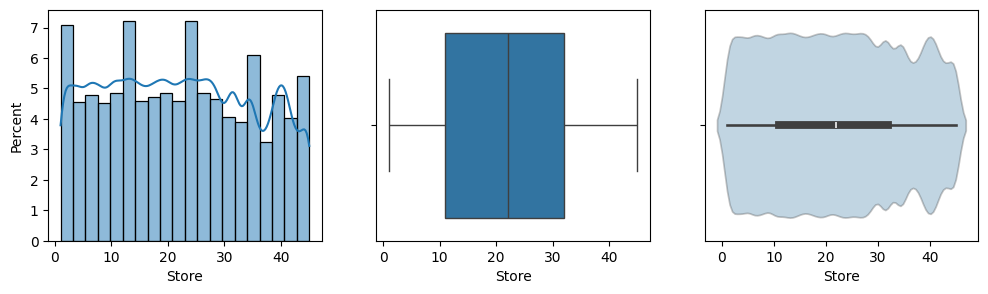

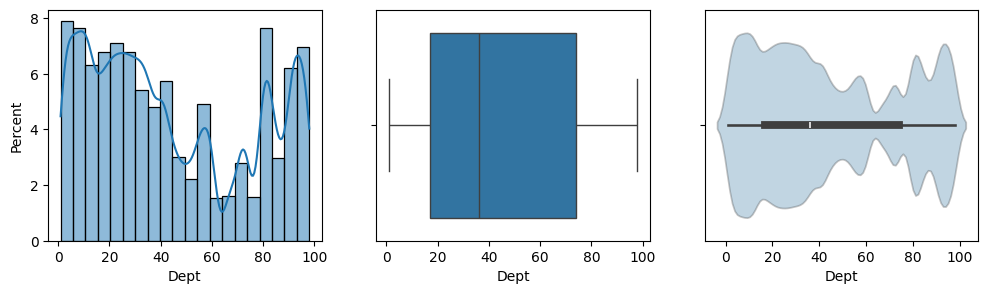

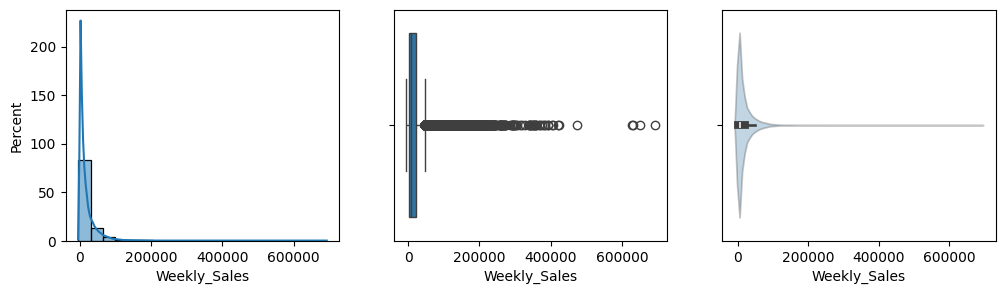

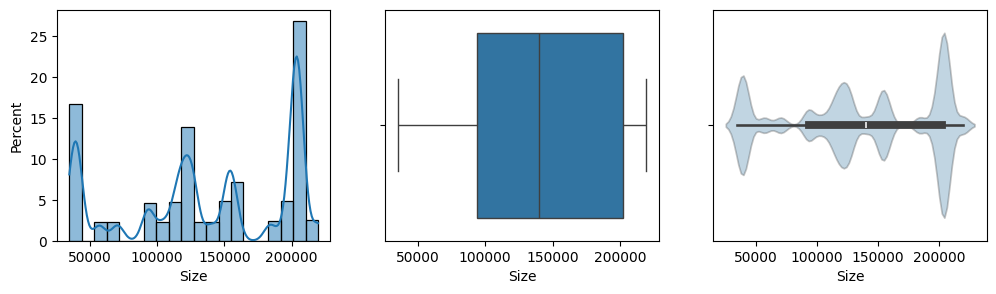

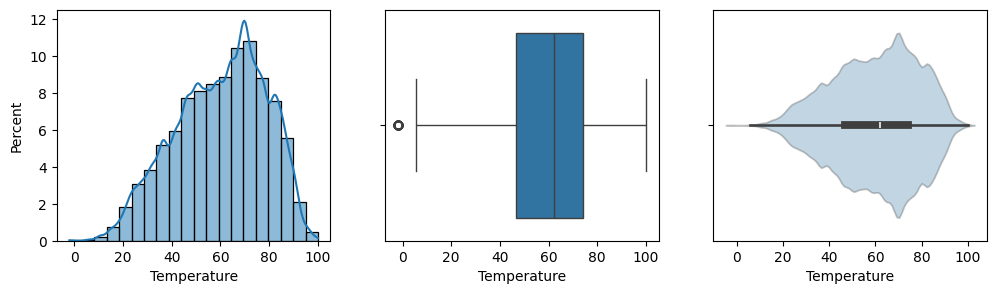

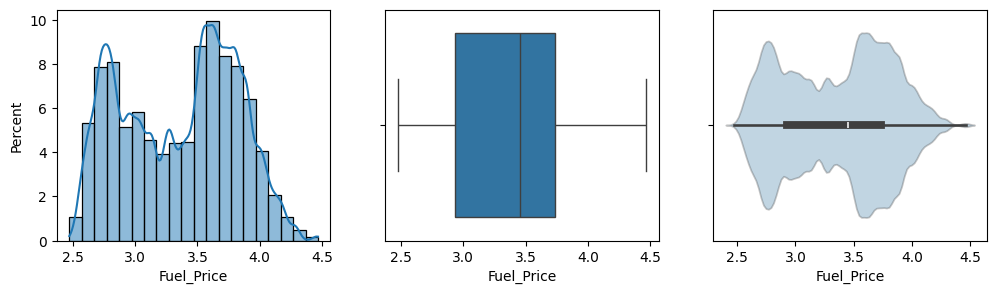

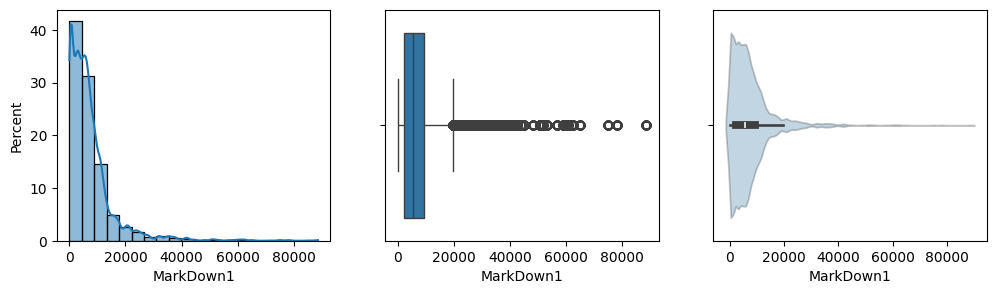

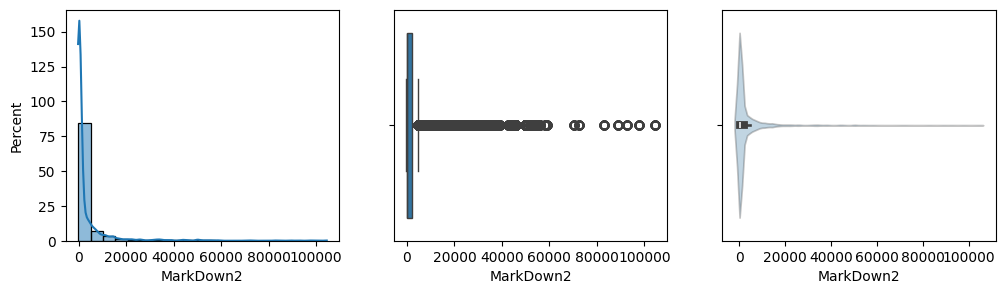

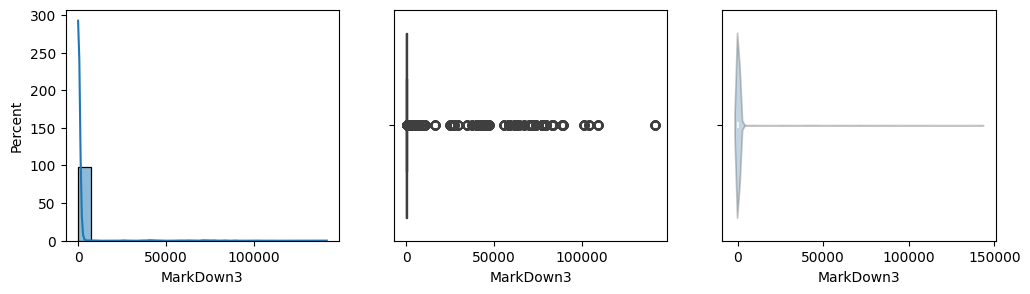

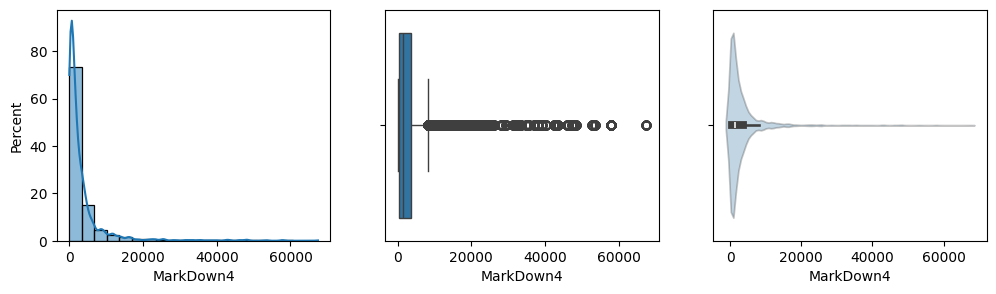

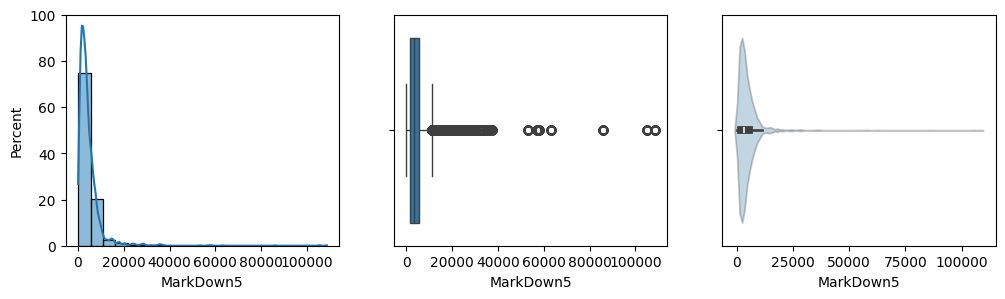

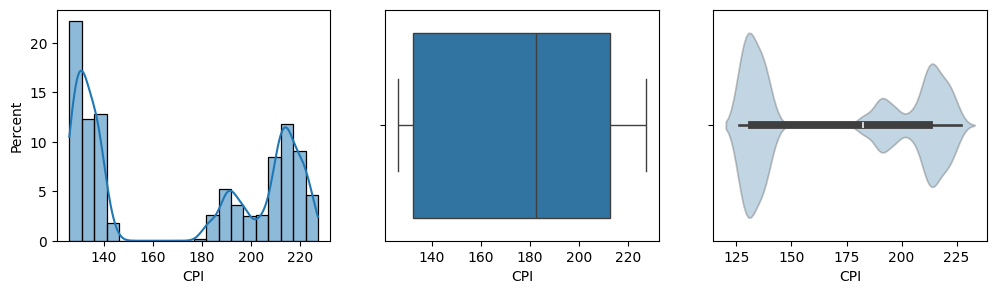

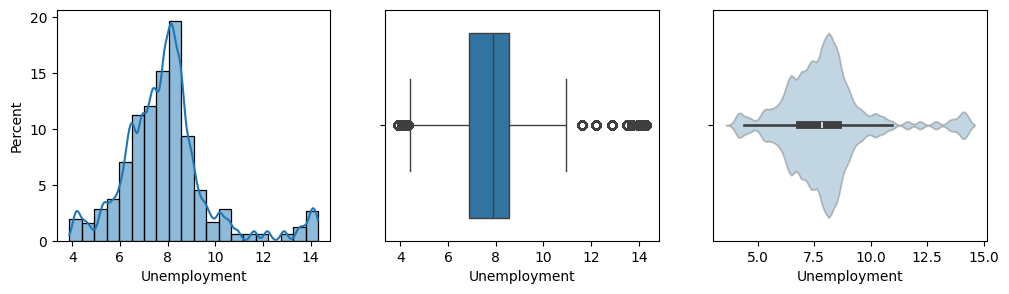

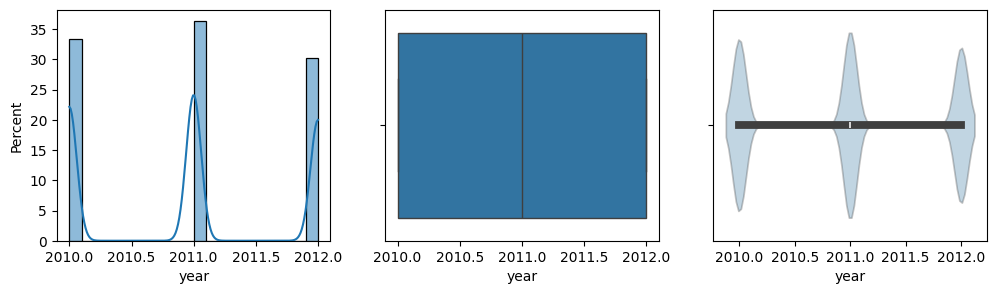

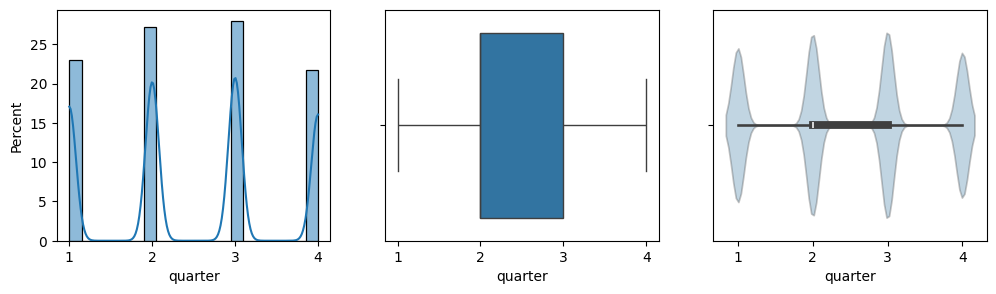

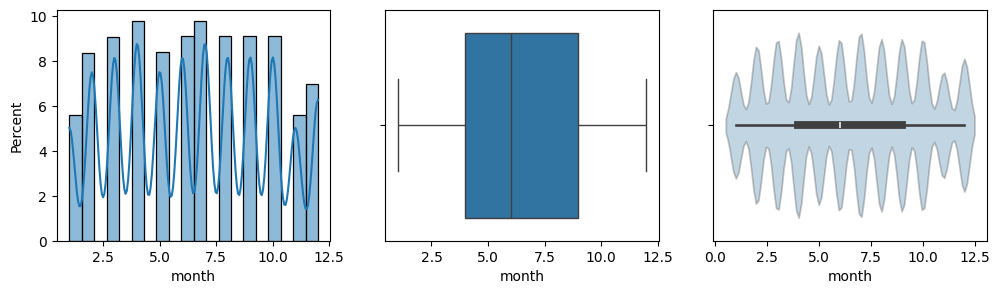

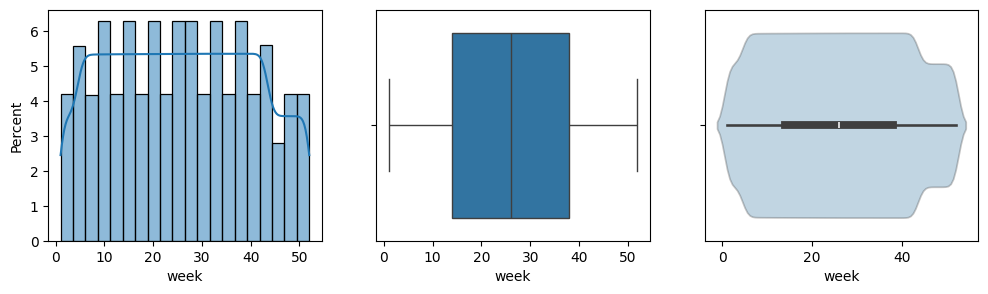

/var/folders/nq/ppxgb7w54v79rqcw67fgvbxr0000gn/T/ipykernel_39434/1788149768.py:80: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(x_labels_1, rotation=45)


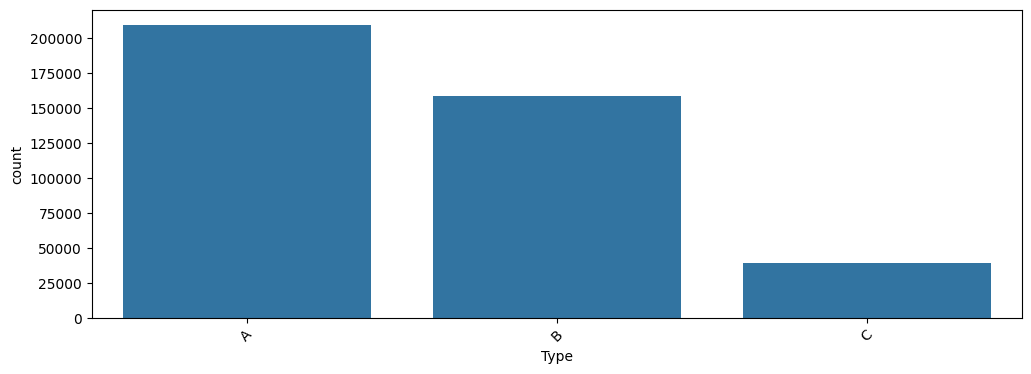

/var/folders/nq/ppxgb7w54v79rqcw67fgvbxr0000gn/T/ipykernel_39434/1788149768.py:80: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(x_labels_1, rotation=45)


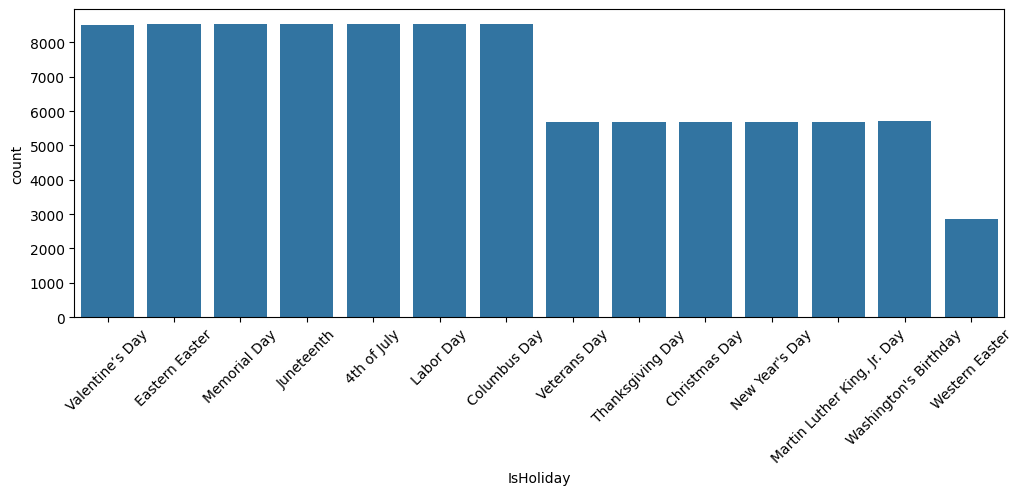

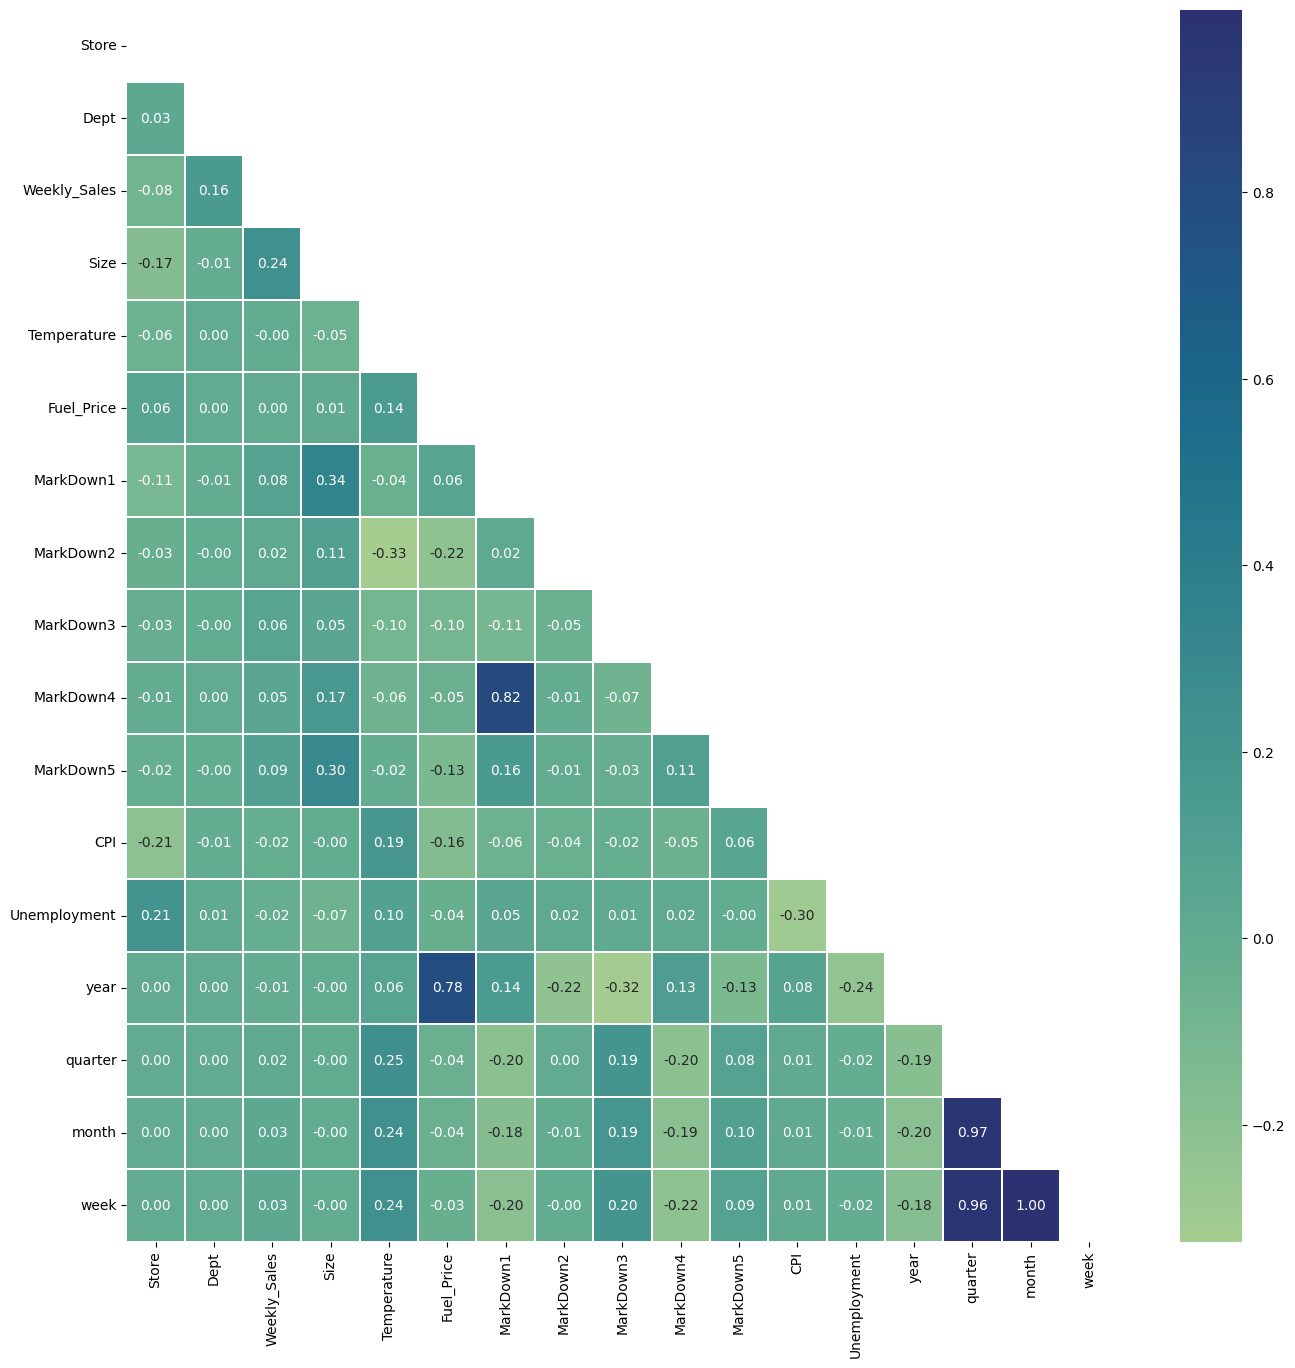

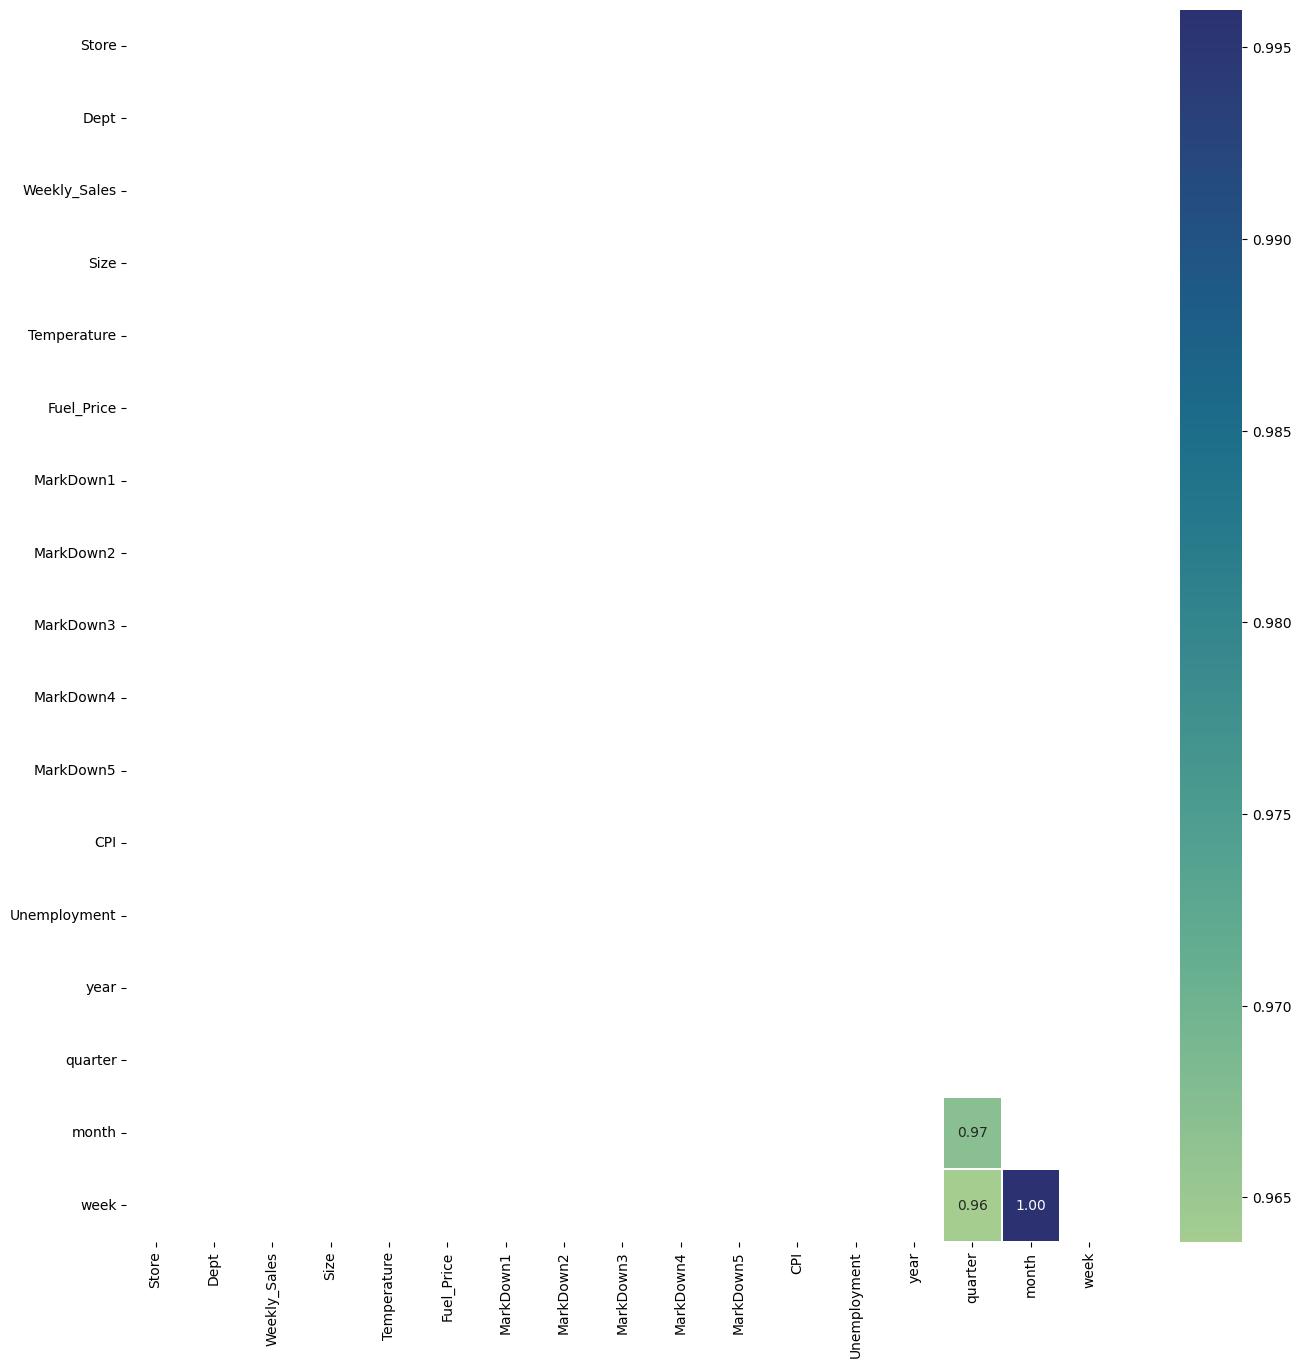

In [15]:
eda.plot_all()

- Findings
0) Overall data completion is good
1) Skewed distribution: MarkDowns & Weekly Sales
2) CPI: No data for 140-180
3) Negative & Null values on MarkDowns
4) Negative values on Weekly Sales; Return? replaced by zero
5) No correlated columns among features; ignore date related columns

## Specific EDA

### Check trend, seasonality

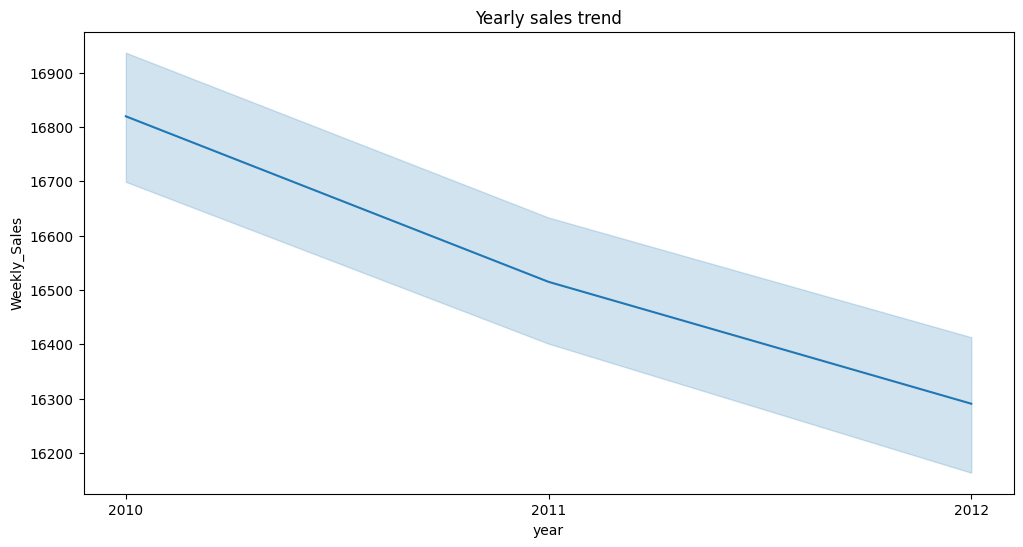

In [16]:
# Yearly sales trend
plt.figure(figsize=(12,6))
sns.lineplot(data=merged_train_df, x="year", y="Weekly_Sales")
plt.xticks([2010, 2011, 2012])
plt.title("Yearly sales trend")
plt.show()

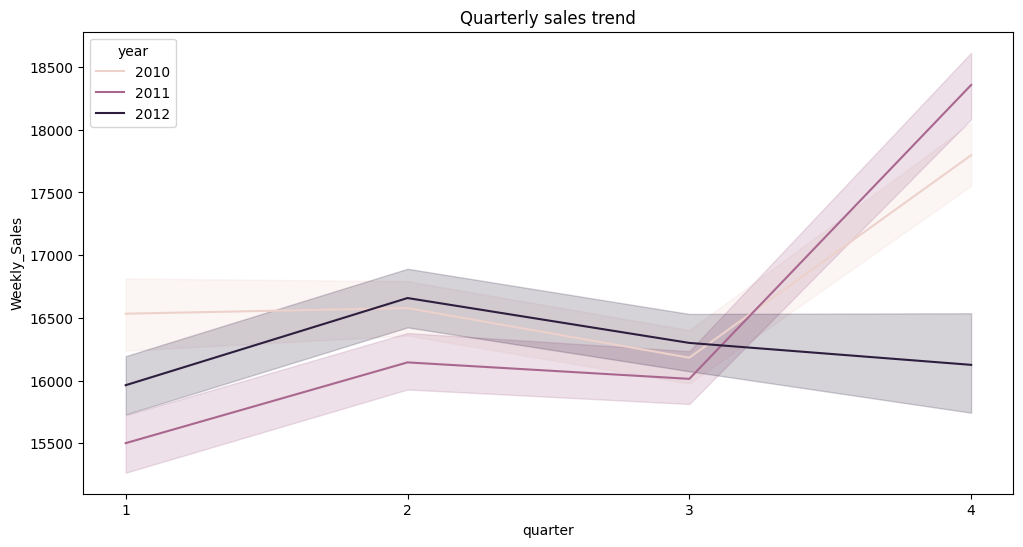

In [17]:
# Quarterly sales trend
plt.figure(figsize=(12,6))
sns.lineplot(data=merged_train_df, x="quarter", y="Weekly_Sales", hue="year")
plt.xticks([1, 2, 3, 4])
plt.title("Quarterly sales trend")
plt.show()

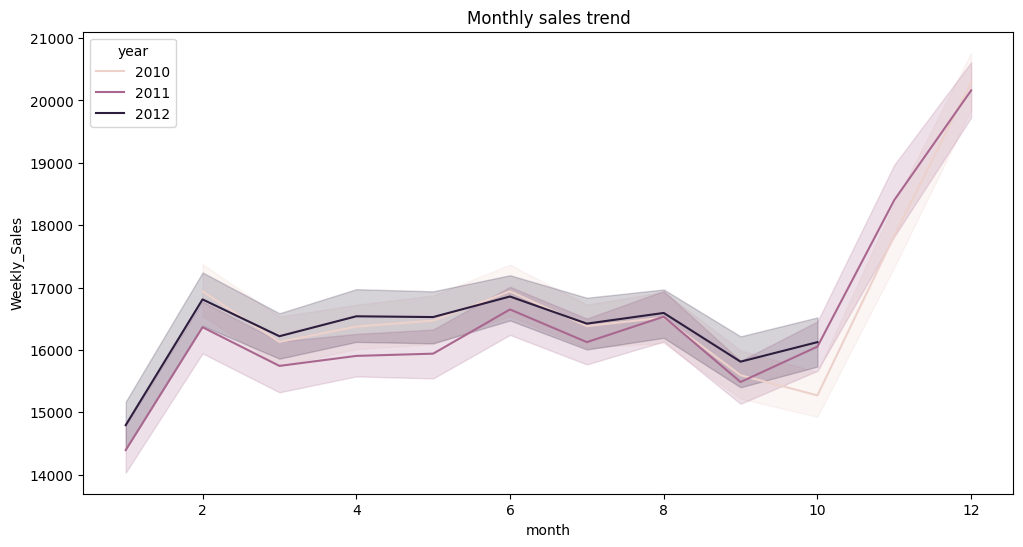

In [18]:
# Monthly sales trend
plt.figure(figsize=(12,6))
sns.lineplot(data=merged_train_df, x="month", y="Weekly_Sales", hue="year")
plt.title("Monthly sales trend")
plt.show()

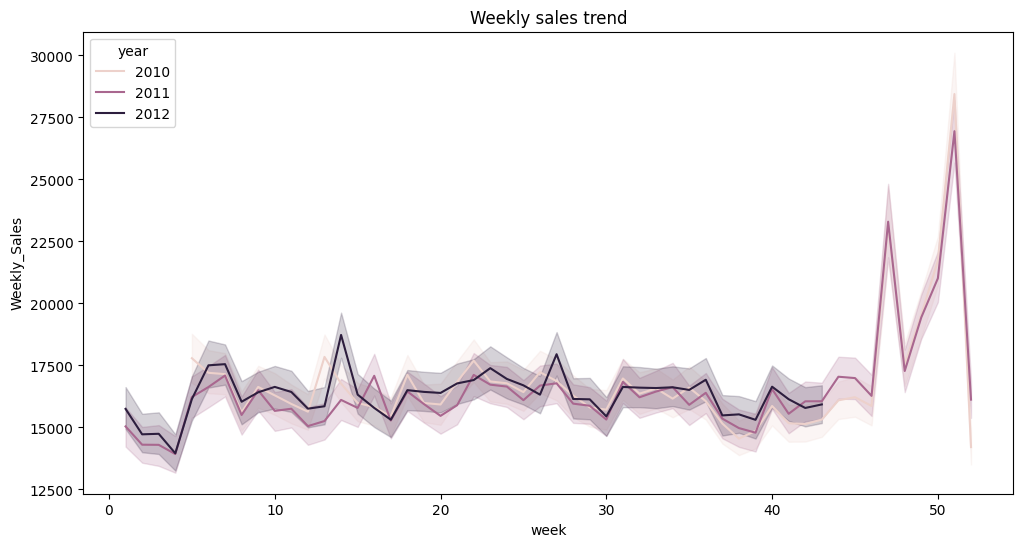

In [19]:
# Weekly sales trend
plt.figure(figsize=(12,6))
sns.lineplot(data=merged_train_df, x="week", y="Weekly_Sales", hue="year")
plt.title("Weekly sales trend")
plt.show()

- Findings
0) Clear seasonal pattern on Month (Nov & Dec) and Week (higher 48-52)

### Weekly Sales by Store, Dept, Type, Size

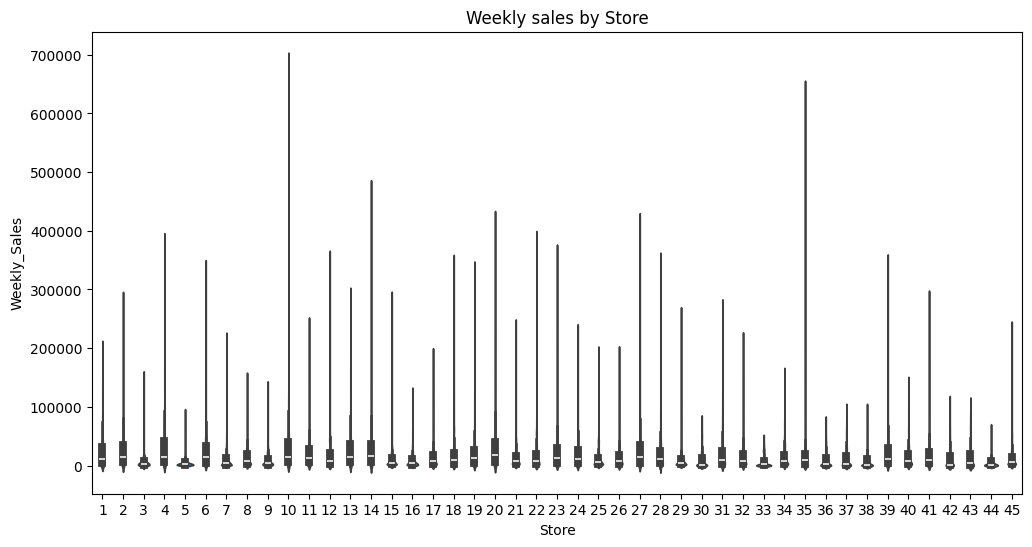

In [20]:
# Weekly sales by Store
plt.figure(figsize=(12,6))
sns.violinplot(data=merged_train_df, x="Store", y="Weekly_Sales")
plt.title("Weekly sales by Store")
plt.show()

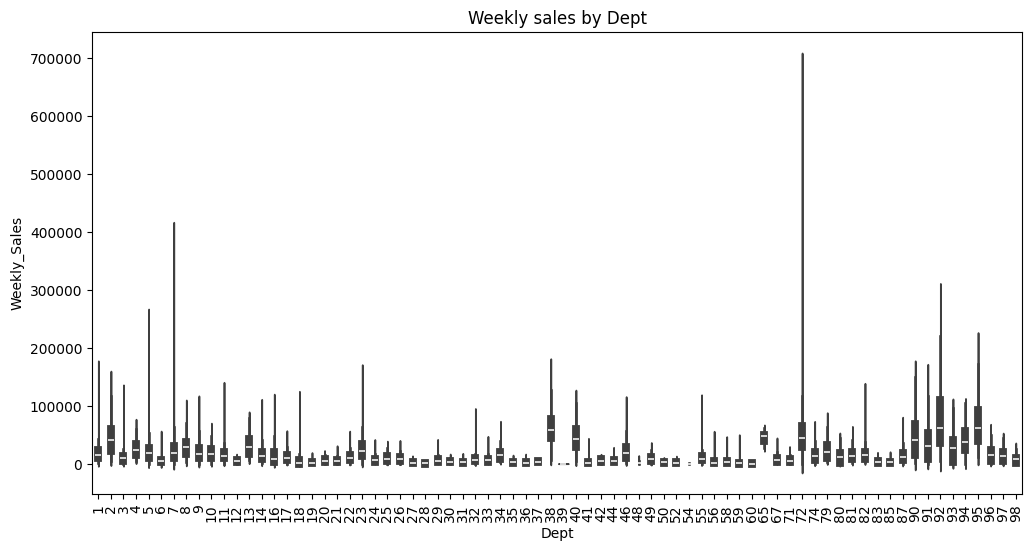

In [21]:
# Weekly sales by Dept
plt.figure(figsize=(12,6))
sns.violinplot(data=merged_train_df, x="Dept", y="Weekly_Sales")
plt.xticks(rotation=90)
plt.title("Weekly sales by Dept")
plt.show()

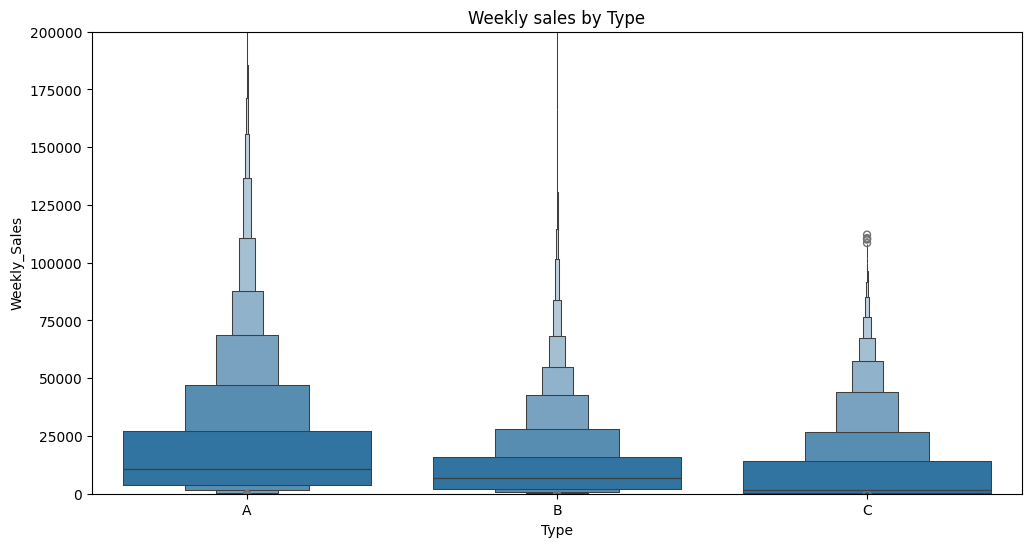

In [22]:
# Weekly sales by Type
plt.figure(figsize=(12,6))
sns.boxenplot(data=merged_train_df, x="Type", y="Weekly_Sales")
plt.ylim([0, 200000])
plt.title("Weekly sales by Type")
plt.show()

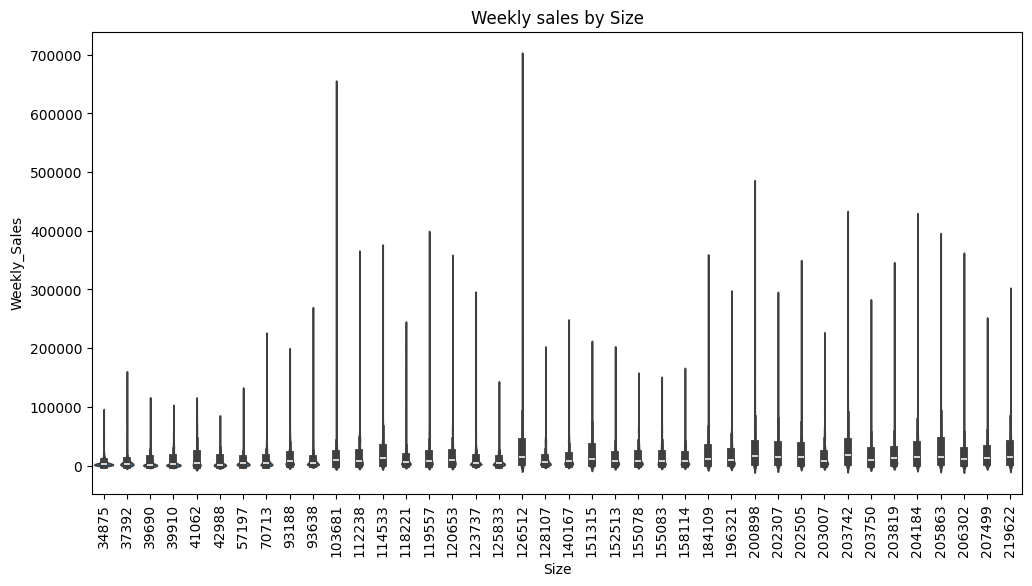

In [23]:
# Weekly sales by Size
plt.figure(figsize=(12,6))
sns.violinplot(data=merged_train_df, x="Size", y="Weekly_Sales")
plt.xticks(rotation=90)
plt.title("Weekly sales by Size")
plt.show()

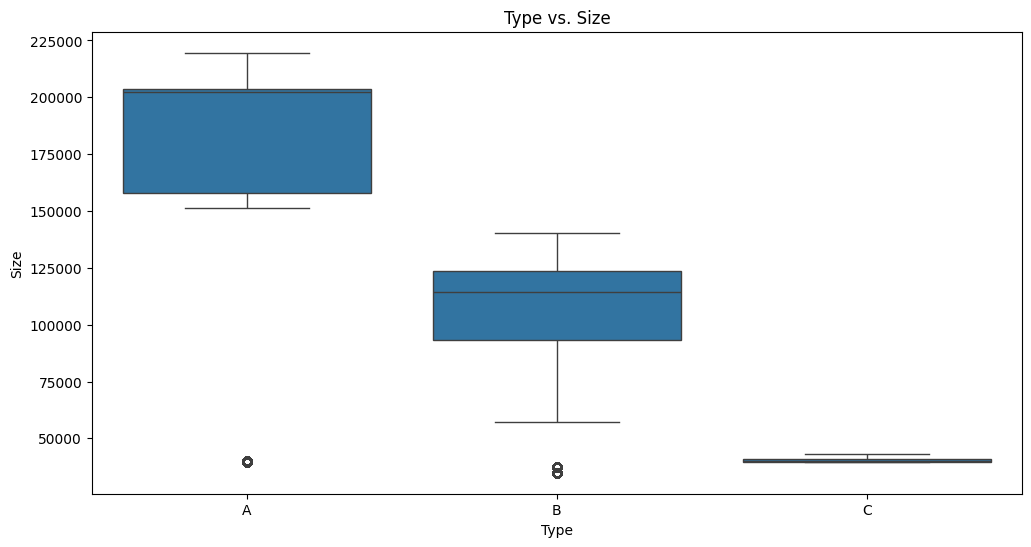

In [24]:
# Type vs. Size?
plt.figure(figsize=(12,6))
sns.boxplot(data=merged_train_df, x="Type", y="Size")
plt.title("Type vs. Size")
plt.show()

- Findings
0) Different weekly sales by store/dept
1) Size linked to type; large > A & small > C and larger stores have more weekly sales

### Check impact of holiday feature

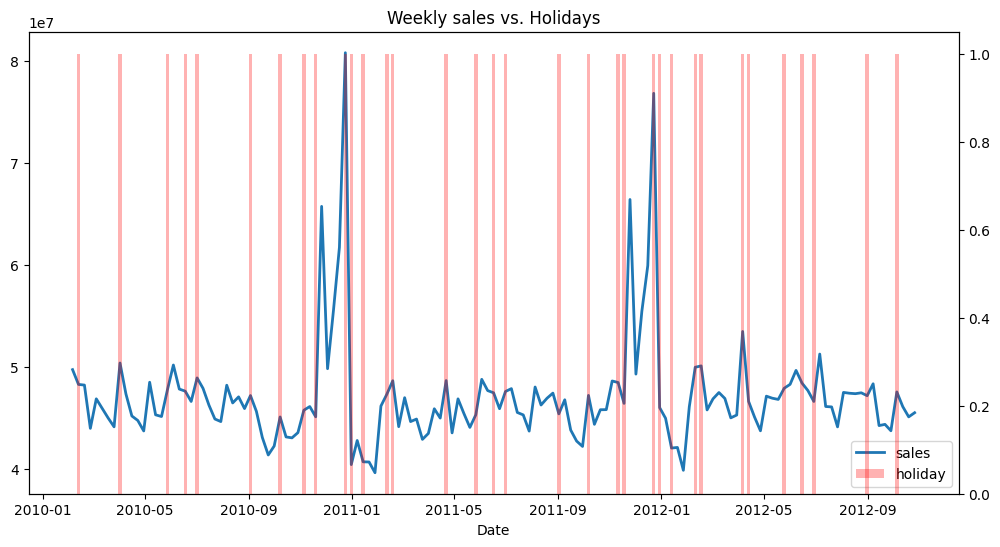

In [25]:
# blue > weekly sales & red > holidays
plot_df = merged_train_df.copy()
plot_df["IsHoliday_int"] = plot_df["IsHoliday"].apply(lambda x: 1 if pd.notnull(x) else 0)
sum_df = plot_df.groupby("Date").agg({"IsHoliday_int": "max", "Weekly_Sales": "sum"}).reset_index()
sum_df

fig = plt.figure(figsize=(12, 6))
ax1 = fig.add_subplot(111)
ax2 = ax1.twinx()
ax1.plot(sum_df["Date"], sum_df["Weekly_Sales"], linewidth=2, label="sales")
ax2.bar(sum_df["Date"], sum_df["IsHoliday_int"], width=4, color="red", alpha=0.3, label="holiday")
ax1.set_xlabel("Date")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1+h2, l1+l2, loc='lower right')
plt.title("Weekly sales vs. Holidays")
plt.show()

- Findings
0) some holidays picked up sales spike but not all > better to do one-hot encoding with holiday name

### Check MarkDown Feature

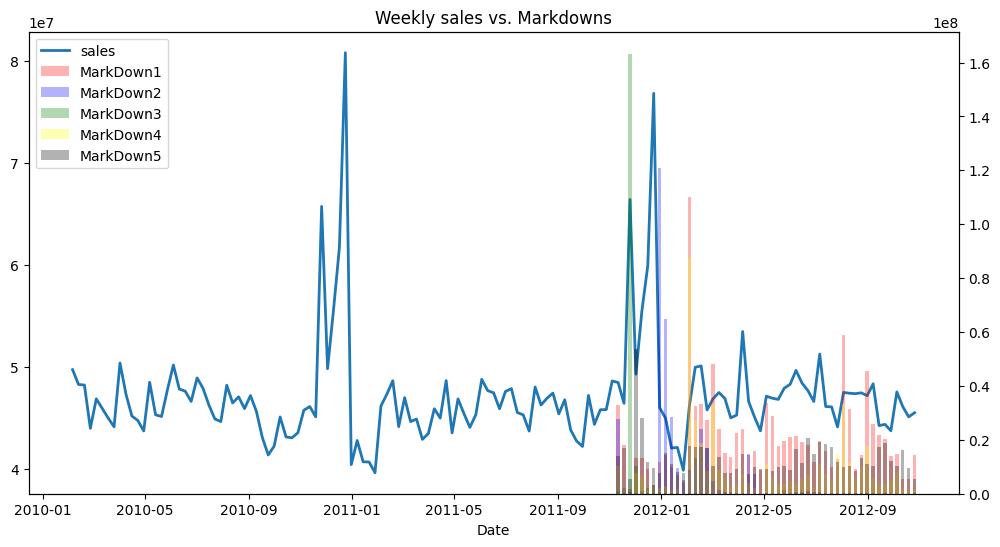

In [26]:
sum_df = merged_train_df.groupby("Date").agg({"MarkDown1": "sum", "MarkDown2": "sum", "MarkDown3": "sum", "MarkDown4": "sum", "MarkDown5": "sum", "Weekly_Sales": "sum"}).reset_index()
sum_df

fig = plt.figure(figsize=(12, 6))
ax1 = fig.add_subplot(111)
ax2 = ax1.twinx()
ax1.plot(sum_df["Date"], sum_df["Weekly_Sales"], linewidth=2, label="sales")
ax2.bar(sum_df["Date"], sum_df["MarkDown1"], width=4, color="red", alpha=0.3, label="MarkDown1")
ax2.bar(sum_df["Date"], sum_df["MarkDown2"], width=4, color="blue", alpha=0.3, label="MarkDown2")
ax2.bar(sum_df["Date"], sum_df["MarkDown3"], width=4, color="green", alpha=0.3, label="MarkDown3")
ax2.bar(sum_df["Date"], sum_df["MarkDown4"], width=4, color="yellow", alpha=0.3, label="MarkDown4")
ax2.bar(sum_df["Date"], sum_df["MarkDown5"], width=4, color="black", alpha=0.3, label="MarkDown5")
ax1.set_xlabel("Date")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1+h2, l1+l2, loc='upper left')
plt.title("Weekly sales vs. Markdowns")
plt.show()

- Findings
0) only 1 year historical data...
1) Need to check the impact of MarkDown

### Check others; CPI, Temp, Unemployment & Fuel_price

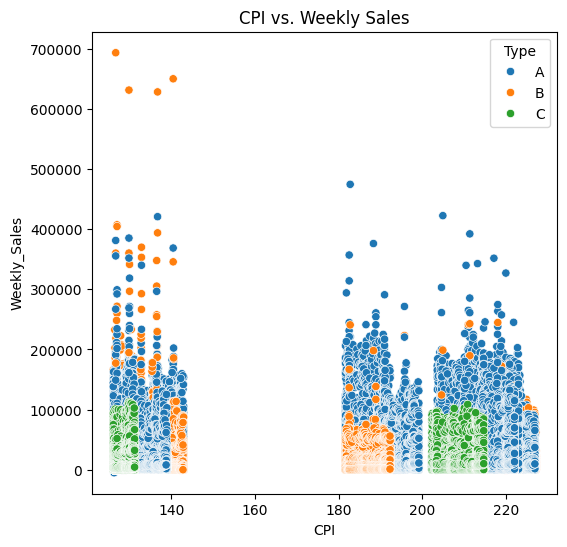

In [27]:
# CPI vs. Weekly Sales
plt.figure(figsize=(6,6))
sns.scatterplot(data=merged_train_df, x="CPI", y="Weekly_Sales", hue="Type")
plt.title("CPI vs. Weekly Sales")
plt.show()

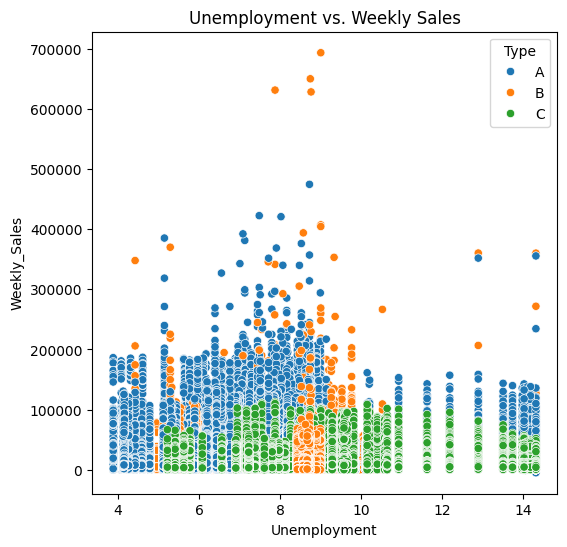

In [28]:
# Unemployment vs. Weekly Sales
plt.figure(figsize=(6,6))
sns.scatterplot(data=merged_train_df, x="Unemployment", y="Weekly_Sales", hue="Type")
plt.title("Unemployment vs. Weekly Sales")
plt.show()

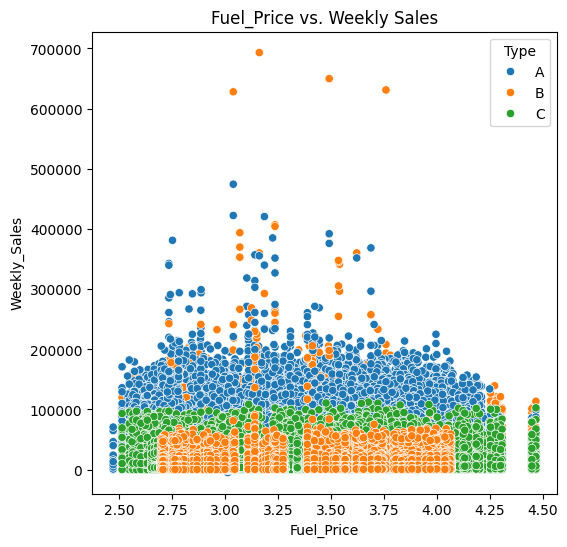

In [29]:
# Fuel_Price vs. Weekly Sales
plt.figure(figsize=(6,6))
sns.scatterplot(data=merged_train_df, x="Fuel_Price", y="Weekly_Sales", hue="Type")
plt.title("Fuel_Price vs. Weekly Sales")
plt.show()

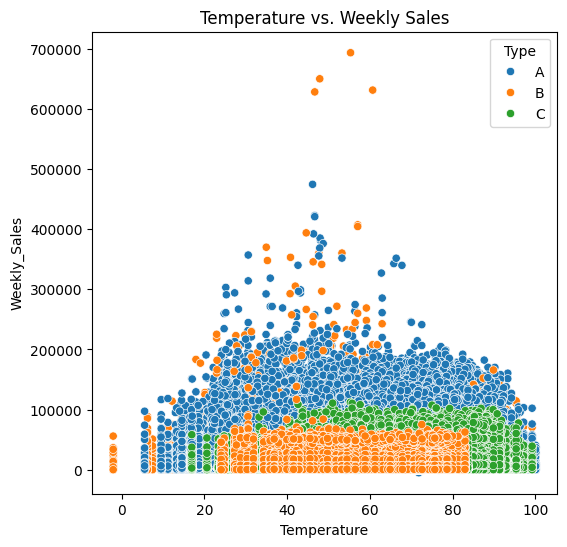

In [30]:
# Temperature vs. Weekly Sales
plt.figure(figsize=(6,6))
sns.scatterplot(data=merged_train_df, x="Temperature", y="Weekly_Sales", hue="Type")
plt.title("Temperature vs. Weekly Sales")
plt.show()

- Findings
0) No strong correlations btw Temperature, CPI, Unemployment & Fuel price vs. weekly sales

# Feature engineering

## Encoding

In [31]:
# check nulls
merged_train_df.isnull().sum()

Date                 0
Store                0
Dept                 0
Weekly_Sales         0
Type                 0
Size                 0
Temperature          0
Fuel_Price           0
MarkDown1       261961
MarkDown2       299350
MarkDown3       274804
MarkDown4       276216
MarkDown5       261286
CPI                  0
Unemployment         0
year                 0
quarter              0
month                0
week                 0
IsHoliday       310067
dtype: int64

In [32]:
# Store type mapping: A,B,C to 3-2-1 (A larger store & C smaller score based on EDA so this mapping might make sense)
type_group = {'A': 3, 'B': 2, 'C': 1}  # changing A,B,C to 1-2-3
merged_train_df['Type'] = merged_train_df['Type'].replace(type_group)
# merged_test_df['Type'] = merged_test_df['Type'].replace(type_group)

/var/folders/nq/ppxgb7w54v79rqcw67fgvbxr0000gn/T/ipykernel_39434/1369258846.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  merged_train_df['Type'] = merged_train_df['Type'].replace(type_group)


In [33]:
from sklearn.preprocessing import OneHotEncoder

# One-hot encoding for holiday
encoder = OneHotEncoder(sparse_output=False)
onehot_encoded = encoder.fit_transform(merged_train_df[["IsHoliday"]])
onehot_encoded_df = pd.DataFrame(onehot_encoded, columns=encoder.get_feature_names_out(["IsHoliday"]))
merged_train_df = pd.concat([merged_train_df, onehot_encoded_df], axis=1)
merged_train_df = merged_train_df.drop(columns=["IsHoliday", "IsHoliday_nan"], axis=1)

In [34]:
# fill in 0 for null values and negative values
mrkdw_cols = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5", "Weekly_Sales"]
merged_train_df[mrkdw_cols] = merged_train_df[mrkdw_cols].where(merged_train_df[mrkdw_cols]>=0, 0)

In [35]:
import pandas as pd
from typing import Union, List
from itertools import product
from scipy.stats import zscore, median_abs_deviation, iqr
from sklearn.cluster import KMeans, MeanShift, Birch
from sklearn.preprocessing import LabelEncoder, KBinsDiscretizer


def feature_substract_columns(df: pd.DataFrame, base_col: str, sub_col: str, new_col: str, neg_zero: bool = False) -> pd.DataFrame:
    df[new_col] = df[base_col] - df[sub_col]

    if neg_zero:
        df[new_col] = df[new_col].clip(lower=0)

    return df

def feature_count_words(df: pd.DataFrame, col: str, new_col: str, delimiter: str) -> pd.DataFrame:
    df[new_col] = [len(x.split(delimiter)) for x in df[col].tolist()]

    return df

def feature_label_encode(df: pd.DataFrame, cols: list) -> pd.DataFrame:
    le = LabelEncoder()
    df[cols] = le.fit_transform(df[cols])

    return df, le

def feature_multiply_columns(df: pd.DataFrame, base_col: str, mul_col: str, new_col:str, decimeter: int) -> pd.DataFrame:
    df[new_col] = df[base_col] * df[mul_col]

    if decimeter is not None:
        df[new_col] = df[new_col] / decimeter

    return df

def feature_devide_columns(df: pd.DataFrame, base_col: str, dev_col: str, new_col:str, decimeter: int = None) -> pd.DataFrame:
    df[new_col] = df[base_col] / df[dev_col]

    if decimeter is not None:
        df[new_col] = df[new_col] * decimeter

    return df

def feature_lag_values(df: pd.DataFrame, sort_col: str, col: str, lag: list, grp_col: Union[str, List] = None, impute_method: str = "zeros") -> pd.DataFrame:
    if grp_col:
        for n in lag:
            df[f"{col}_lag{n}"] = df.sort_values(by=sort_col).groupby(grp_col)[col].shift(n)
    else:
        for n in lag:
            df[f"{col}_lag{n}"] = df.sort_values(by=sort_col)[col].shift(n)
    
    if impute_method == "zeros":
        for n in lag:
            df[f"{col}_lag{n}"] = df[f"{col}_lag{n}"].fillna(0)
    else:
        for n in lag:
            df[f"{col}_lag{n}"] = df[f"{col}_lag{n}"].fillna(np.NaN)

    return df


In [36]:
# Generate lags features
sort_col = "Date"
grp_col = ["Store", "Dept"]
cols = ["Weekly_Sales"]
lags = [1,2]

for col in cols:
    merged_train_df = feature_lag_values(merged_train_df, sort_col, col, lags, grp_col)
    # df = feature_hist_agg_values(df, sort_col, col, lags, func, grp_col)

merged_train_df

,Date,Store,Dept,Weekly_Sales,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,...,"IsHoliday_Martin Luther King, Jr. Day",IsHoliday_Memorial Day,IsHoliday_New Year's Day,IsHoliday_Thanksgiving Day,IsHoliday_Valentine’s Day,IsHoliday_Veterans Day,IsHoliday_Washington's Birthday,IsHoliday_Western Easter,Weekly_Sales_lag1,Weekly_Sales_lag2
0,2010-02-05,1,1,24924.50,3,151315,42.31,2.572,0.00,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00
1,2010-02-12,1,1,46039.49,3,151315,38.51,2.548,0.00,0.00,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,24924.50,0.00
2,2010-02-19,1,1,41595.55,3,151315,39.93,2.514,0.00,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,46039.49,24924.50
3,2010-02-26,1,1,19403.54,3,151315,46.63,2.561,0.00,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,41595.55,46039.49
4,2010-03-05,1,1,21827.90,3,151315,46.50,2.625,0.00,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19403.54,41595.55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
406814,2012-09-28,45,98,508.37,2,118221,64.88,3.997,4556.61,20.64,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,467.30,605.96
406815,2012-10-05,45,98,628.10,2,118221,64.89,3.985,5046.74,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,508.37,467.30
406816,2012-10-12,45,98,1061.02,2,118221,54.47,4.000,1956.28,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,628.10,508.37
406817,2012-10-19,45,98,760.01,2,118221,56.47,3.969,2004.02,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1061.02,628.10


In [38]:
# Final check
merged_train_df.isnull().sum()

Date                                     0
Store                                    0
Dept                                     0
Weekly_Sales                             0
Type                                     0
Size                                     0
Temperature                              0
Fuel_Price                               0
MarkDown1                                0
MarkDown2                                0
MarkDown3                                0
MarkDown4                                0
MarkDown5                                0
CPI                                      0
Unemployment                             0
year                                     0
quarter                                  0
month                                    0
week                                     0
IsHoliday_4th of July                    0
IsHoliday_Christmas Day                  0
IsHoliday_Columbus Day                   0
IsHoliday_Eastern Easter                 0
IsHoliday_J

# Modelling: Hyper param tuning & Evaluation

## Define models - time series regression  
1) SARIMA (sep model)  
2) Elastic Net (all)  
3) RF (all)  
4) LGBM (all)  
5) LSTM/AR LSTM (sep model)  
6) GRU (sep model)  

In [39]:
import re

# modify column names to avoid error due to column name
merged_train_df = merged_train_df.rename(columns = lambda x:re.sub('[^A-Za-z0-9_]+', '', x))

In [40]:
merged_train_df.columns

Index(['Date', 'Store', 'Dept', 'Weekly_Sales', 'Type', 'Size', 'Temperature',
       'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4',
       'MarkDown5', 'CPI', 'Unemployment', 'year', 'quarter', 'month', 'week',
       'IsHoliday_4thofJuly', 'IsHoliday_ChristmasDay',
       'IsHoliday_ColumbusDay', 'IsHoliday_EasternEaster',
       'IsHoliday_Juneteenth', 'IsHoliday_LaborDay',
       'IsHoliday_MartinLutherKingJrDay', 'IsHoliday_MemorialDay',
       'IsHoliday_NewYearsDay', 'IsHoliday_ThanksgivingDay',
       'IsHoliday_ValentinesDay', 'IsHoliday_VeteransDay',
       'IsHoliday_WashingtonsBirthday', 'IsHoliday_WesternEaster',
       'Weekly_Sales_lag1', 'Weekly_Sales_lag2'],
      dtype='object')

In [41]:
from sklearn.model_selection import TimeSeriesSplit

tss = TimeSeriesSplit(n_splits = 2, gap=0)
train_cut_date = "2012-10-01"
max_lags  = 2
df = merged_train_df.copy()

df.set_index("Date", inplace=True)
df.sort_index(inplace=True)
# base date > data will be split
base_date = min(df.index) + pd.Timedelta(weeks=max_lags)
print(base_date)
df = df[base_date:]

# train-test data split based on base date
tr_df = df[:train_cut_date]
te_df = df[train_cut_date:]

tgt_col = "Weekly_Sales"
X_train = tr_df.drop(columns=tgt_col, axis=1)
y_train = tr_df[tgt_col]

X_test = te_df.drop(columns=tgt_col, axis=1)
y_test = te_df[tgt_col]

2010-02-19 00:00:00


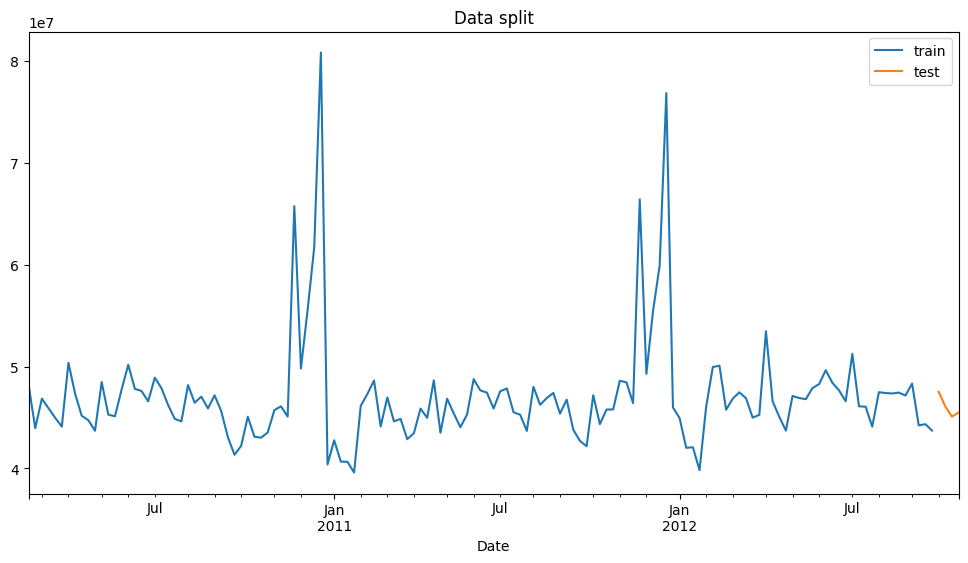

In [42]:
# Display data split
plt.figure(figsize=(12,6))
y_train.groupby("Date").sum().plot(label="train")
y_test.groupby("Date").sum().plot(label="test")
plt.legend()
plt.title("Data split")
plt.show()

In [43]:
# store each model evaluation and data frames
best_models = {}
output_all_tr_dict = {}
output_all_pred_dict = {}

### 1. SARIMA

Model will be implemented for Store & Dept combination but it takes too much time to find params for each model.  
Approach will be general params will be defined with weekly aggregated data and apply it to each combination.

In [44]:
# Define ARIMA params with aggregated data
from pmdarima import auto_arima

df_arima = tr_df.copy()

data = df_arima.groupby("Date")["Weekly_Sales"].sum()
model = auto_arima(data, seasonal=False, stepwise=True, trace=True, error_action='ignore', suppress_warnings=True)
model.summary()

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=4657.359, Time=0.26 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=5233.527, Time=0.01 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=inf, Time=0.01 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=5145.611, Time=0.02 sec
 ARIMA(1,0,2)(0,0,0)[0]             : AIC=inf, Time=0.05 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=inf, Time=0.07 sec
 ARIMA(3,0,2)(0,0,0)[0]             : AIC=inf, Time=0.13 sec
 ARIMA(2,0,3)(0,0,0)[0]             : AIC=inf, Time=0.08 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=4655.136, Time=0.02 sec
 ARIMA(0,0,2)(0,0,0)[0]             : AIC=5119.723, Time=0.02 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=inf, Time=0.01 sec
 ARIMA(1,0,1)(0,0,0)[0] intercept   : AIC=4632.893, Time=0.02 sec
 ARIMA(0,0,1)(0,0,0)[0] intercept   : AIC=4636.569, Time=0.01 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=4631.756, Time=0.01 sec
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=4645.937, Time=0.01 s

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                  137
Model:               SARIMAX(2, 0, 0)   Log Likelihood               -2311.874
Date:                Mon, 20 Jan 2025   AIC                           4631.749
Time:                        20:19:56   BIC                           4643.428
Sample:                    02-19-2010   HQIC                          4636.495
                         - 09-28-2012                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept   2.743e+07   9.68e-10   2.83e+16      0.000    2.74e+07    2.74e+07
ar.L1          0.2946      0.050      5.886      0.000       0.197       0.393
ar.L2          0.1224      0.054      2.259      0.024       0.016       0.229
sigma2      2.687e+13   9.28e-16    2.9e+28      0.000    2.69e+13    2.69e+13
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):              1037.56
Prob(Q):                              0.96   Prob(JB):                         0.00
Heteroskedasticity (H):               0.82   Skew:                             2.52
Prob(H) (two-sided):                  0.51   Kurtosis:                        15.50
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 2.35e+42. Standard errors may be unstable.
"""

In [45]:
import time
import pandas as pd
from pmdarima import auto_arima
from joblib import Parallel, delayed
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA

# Get unique store-dept combinations for imputation
combinations = df_arima[["Store", "Dept"]].drop_duplicates()
combinations

# for calculate executed time
train_time = 0
test_time = 0

# Define the function to fit ARIMA for each store-dept combination
def fit_predict_arima(store_id, dept, data, seasonal_period=4):

    # Filter data for the specific store-dept combination
    df = data[(data["Store"] == store_id) & (data["Dept"] == dept)]
    
    # Define the target variable
    y = df["Weekly_Sales"] 
    y.index = pd.DatetimeIndex(y.index.values, freq="W-FRI")
    
    # Fit the ARIMA w/o seasonality orders
    start_time = time.time()
    model = SARIMAX(endog=y, order=(2,0,0), seasonal_order=(0,0,0,0)).fit(disp=False)
    end_time = time.time()
    train_time = end_time - start_time

    # store train prediction to dataframe
    fcst_train_df = pd.DataFrame({
        "Date": df.index,
        "Store": store_id,
        "Dept": dept,
        "Weekly_Sales": df["Weekly_Sales"],
        "Weekly_Sales_pred": model.predict()
    })
    start_time = time.time()
    forecast = model.forecast(4)  # Forecast 4 weeks ahead
    end_time = time.time()
    test_time = end_time - start_time

    # Generate future dates for the forecast period
    last_date = df_arima.index.max()
    forecast_dates = pd.date_range(start=last_date, periods=4+1, freq='W-FRI')[1:]

    # Create a DataFrame for the forecast results
    forecast_df = pd.DataFrame({
        "Date": forecast_dates,
        "Store": store_id,
        "Dept": dept,
        "Weekly_Sales_pred": forecast,
    })
 
    # Return the outputs
    return fcst_train_df, forecast_df, train_time, test_time

start_time = time.time()

# List to store forecast DataFrames for each combination
forecast_results = []
forecast_train_results = []

# Iterate through each store-dept combination and fit ARIMA
for _, row in combinations.iterrows():
    store_id = row['Store']
    dept = row['Dept']
    forecast_train_df, forecast_df, tr_time, tst_time = fit_predict_arima(store_id, dept, df_arima)
    forecast_train_results.append(forecast_train_df)
    forecast_results.append(forecast_df)
    train_time += tr_time
    test_time += tst_time
end_time = time.time()

print("Execution time: %s seconds" %(end_time - start_time))

# Combine all forecast results into a single DataFrame
final_forecast_train_df = pd.concat(forecast_train_results, ignore_index=True)
final_forecast_df = pd.concat(forecast_results, ignore_index=True)

final_forecast_train_df["Weekly_Sales_pred"] = final_forecast_train_df["Weekly_Sales_pred"].apply(lambda x: x if x>=0 else 0)
final_forecast_df["Weekly_Sales_pred"] = final_forecast_df["Weekly_Sales_pred"].apply(lambda x: x if x>=0 else 0)

# Print or save the forecast data
print(final_forecast_train_df)
print(final_forecast_df)
print("train time =", train_time, "test time =", test_time)

/Users/leehy0816/anaconda3/envs/bootcamp/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/leehy0816/anaconda3/envs/bootcamp/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/leehy0816/anaconda3/envs/bootcamp/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/leehy0816/anaconda3/envs/bootcamp/lib/python3.11/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive p

Execution time: 55.851900815963745 seconds
             Date  Store  Dept  Weekly_Sales  Weekly_Sales_pred
0      2010-02-19      6    95      79921.51           0.000000
1      2010-02-26      6    95      77582.92       79530.353571
2      2010-03-05      6    95      84641.44       78219.706688
3      2010-03-12      6    95      85516.83       81742.588036
4      2010-03-19      6    95     101969.74       84927.451957
...           ...    ...   ...           ...                ...
389795 2012-08-31     19    39          4.47           0.000000
389796 2012-09-07     19    39         13.41           3.698619
389797 2012-09-14     19    39         20.86          17.500226
389798 2012-09-21     19    39         20.86          20.981741
389799 2012-09-28     19    39         11.92          13.780781

[389800 rows x 5 columns]
            Date  Store  Dept  Weekly_Sales_pred
0     2012-10-05      6    95       82502.667051
1     2012-10-12      6    95       81672.023090
2     2012-10-1

### Evaluation

In [46]:
def cal_mape(df):
    overall_mape = df["gap"].sum()/df["Weekly_Sales"].sum()
    mape_by_week = df.groupby("Date").sum()
    mape_by_week["MAPE"] = mape_by_week["gap"]/mape_by_week["Weekly_Sales"]

    return overall_mape, mape_by_week


In [47]:
# train MAPE calculation
final_forecast_train_df = final_forecast_train_df.reset_index()
final_forecast_train_df = final_forecast_train_df[final_forecast_train_df["Date"]>"2010-02-26"]
final_forecast_train_df["gap"] = abs(final_forecast_train_df["Weekly_Sales"] - final_forecast_train_df["Weekly_Sales_pred"])
output_all_tr_dict.update({"ARIMA": final_forecast_train_df})

mape_df = final_forecast_train_df[final_forecast_train_df["Weekly_Sales"]>0]
overall_mape, mape_by_week = cal_mape(mape_df)
print("overall MAPE =", overall_mape)
print(mape_by_week)

overall MAPE = 0.1282325868624574
                index  Store    Dept  Weekly_Sales  Weekly_Sales_pred  \
Date                                                                    
2010-03-05  536407268  61272  121639   46845058.46       4.391858e+07   
2010-03-12  538171341  61482  122156   45902679.59       4.468841e+07   
2010-03-19  538446070  61555  122182   44961336.74       4.530096e+07   
2010-03-26  538260895  61491  122462   44096608.94       4.443950e+07   
2010-04-02  538499186  61488  122378   50362686.13       4.333044e+07   
...               ...    ...     ...           ...                ...   
2012-08-31  555101107  62681  125027   47150534.40       4.644016e+07   
2012-09-07  557873511  63039  125490   48320689.60       4.597465e+07   
2012-09-14  557733032  63017  125332   44215868.24       4.630338e+07   
2012-09-21  558190034  63007  125461   44336004.16       4.449011e+07   
2012-09-28  557902447  63004  125405   43707995.40       4.325507e+07   

                

In [48]:
# Store output
best_models["ARIMA"] = {"estimator": SARIMAX, "params": {"order": (2,0,0), "seasonal_order":(0,0,0,0)}, "train_score": overall_mape}

In [49]:
# test MAPE calculation
final_forecast_df= final_forecast_df.reset_index()

y_act = te_df[["Store", "Dept", "Weekly_Sales"]].reset_index()
output_all = y_act.merge(final_forecast_df[["Date", "Store", "Dept", "Weekly_Sales_pred"]], on=["Date", "Store", "Dept"], how="left")
output_all["gap"] = abs(output_all["Weekly_Sales"] - output_all["Weekly_Sales_pred"])
output_all_pred_dict.update({"ARIMA": output_all})

mape_df = output_all[output_all["Weekly_Sales"]>0]
overall_mape, mape_by_week = cal_mape(mape_df)
print("overall MAPE =", overall_mape)
print(mape_by_week)

best_models["ARIMA"].update({"test_score": overall_mape})

overall MAPE = 0.12250419754879516
            Store    Dept  Weekly_Sales  Weekly_Sales_pred           gap  \
Date                                                                       
2012-10-05  63020  125487   47521428.20       4.291282e+07  5.473438e+06   
2012-10-12  63007  125418   46078872.70       4.211255e+07  5.468554e+06   
2012-10-19  63065  125503   45073388.03       4.139797e+07  5.153766e+06   
2012-10-26  63013  125397   45480779.78       4.070133e+07  6.463938e+06   

                MAPE  
Date                  
2012-10-05  0.115178  
2012-10-12  0.118678  
2012-10-19  0.114342  
2012-10-26  0.142125  


### 2-4. Elastic Net, RF & LGBM

In [50]:
import lightgbm as lgb

from sklearn.linear_model import ElasticNet
from sklearn.ensemble import RandomForestRegressor

# define models as dict
models = {
    "elastic": ElasticNet(),
    "random_forest": RandomForestRegressor(),
    "lightgbm": lgb.LGBMRegressor(),
}

In [51]:
# define hyper parameters for grid search; only 1 param due to high cost of calculation
params = {
    "elastic": {
        "alpha": [0.1, 1],
        # "l1_ratio": [0.3, 0.5],
        # "tol": [0.0001, 0.001],
    },
    "random_forest": {
        "n_estimators": [50, 100],
        # "max_depth": [10, 15],
    },
    "lightgbm": {
        "n_estimators": [50, 100],
        # "learning_rate": [0.05, 0.1],
        # "max_depth": [10, 15],
        "verbose": [-1],
    },
}

In [52]:
"""Modules of repeated usage"""
import numpy as np
import pandas as pd

from typing import Union
from sklearn.model_selection import GridSearchCV


def hyperparam_tuning_gs(model, params: dict, X: pd.DataFrame, y: Union[pd.DataFrame, pd.Series, np.array], scoring: str, cv: int = None) -> dict:
    """Hyper parameter tuning by grid search with cross validation.

    Variables
    ----------
    model: Estimator
        Model estimater (initialized one not trained model)
    params: dict
        Hyper paramters
    X: pd.DataFrame
        Dataframe only with feature columns
    y: pd.DataFrame | pd.Series |
        Dataframe only with feature columns
    cv: int
        Number of split for X-validation
    ----------

    Outputs
    ----------
    best_params: dict
        Hyper parameter from the best model
    ----------
    """
    if cv:
        # use when we specific fold numbers for cv
        gridsearch = GridSearchCV(estimator=model, param_grid=params, cv=cv, scoring=scoring)
        gridsearch.fit(X, y)
    else:
        # cv = 5 (default) will be applied.
        gridsearch = GridSearchCV(estimator=model, param_grid=params, scoring=scoring)
        gridsearch.fit(X, y)

    # store best result
    best_est = gridsearch.best_estimator_
    best_params = gridsearch.best_params_
    best_score = gridsearch.best_score_

    print("best params:", best_params)
    print("best_score:", best_score)

    # return best estimator, params and score
    return best_est, best_params, best_score

## hyper parameter tuning with grid search CV 

In [53]:
import time
from sklearn.metrics import mean_absolute_error

best_models = {}
scoring = "neg_mean_absolute_error"  # objective metrics

# loop grid search for parameter tuning
for model, estimator in models.items():
    print(f"Model: {model}")
    start_time = time.time()
    if len(params[model]) == 0:
        print("Hyperparmeters not defined. Training with default params.")
        estimator.fit(X_train, y_train)
        pred_y = estimator.predict(X_train)
        end_time = time.time()
        score = mean_absolute_error(y_train, pred_y) * (-1)
        print("best_score:", score)
        best_models[model] = {"estimator": estimator, "params": {}, "score": score}
        print("Execution time: %s seconds" %(end_time - start_time))
        print(f"-----------")
        continue
    print(params[model])
    best_est, best_params, best_score = hyperparam_tuning_gs(estimator, params[model], X_train, y_train, scoring)
    end_time = time.time()
    best_models[model] = {"estimator": best_est, "params": best_params, "train_score": best_score}
    print("Execution time: %s seconds" %(end_time - start_time))
    print(f"-----------")

Model: elastic
{'alpha': [0.1, 1]}


/Users/leehy0816/anaconda3/envs/bootcamp/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.357e+11, tolerance: 1.676e+10
  model = cd_fast.enet_coordinate_descent(
/Users/leehy0816/anaconda3/envs/bootcamp/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.636e+12, tolerance: 1.678e+10
  model = cd_fast.enet_coordinate_descent(
/Users/leehy0816/anaconda3/envs/bootcamp/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the

best params: {'alpha': 0.1}
best_score: -2723.170647378346
Execution time: 262.31010007858276 seconds
-----------
Model: random_forest
{'n_estimators': [50, 100]}
best params: {'n_estimators': 100}
best_score: -1892.7929057547458
Execution time: 4845.499670982361 seconds
-----------
Model: lightgbm
{'n_estimators': [50, 100], 'verbose': [-1]}
best params: {'n_estimators': 100, 'verbose': -1}
best_score: -1850.7398042881996
Execution time: 9.115449905395508 seconds
-----------


In [54]:
# MAPE calculation for overall and by week
for mdl_key in best_models.keys():
    print("Model:", mdl_key)
    model = best_models[mdl_key]["estimator"]
    y_pred = model.predict(X_train)
    y_pred_df = pd.DataFrame(y_pred, index=y_train.index, columns=["Weekly_Sales"])
 
    output_all_tr = tr_df[["Store", "Dept", "Weekly_Sales"]].copy()
    output_all_tr["Weekly_Sales_pred"] = y_pred
    output_all_tr["Weekly_Sales_pred"]= output_all_tr["Weekly_Sales_pred"].where(output_all_tr["Weekly_Sales_pred"]>=0, 0)
    output_all_tr["gap"] = abs(output_all_tr["Weekly_Sales"] - output_all_tr["Weekly_Sales_pred"])
    output_all_tr_dict.update({f"{mdl_key}": output_all_tr})

    mape_df = output_all_tr[output_all_tr["Weekly_Sales"]>0]
    overall_mape, mape_by_week = cal_mape(mape_df)    
    print("overall MAPE =", overall_mape)
    print(mape_by_week["MAPE"])

    best_models[mdl_key].update({"train_score": overall_mape})
    print("------------")

Model: elastic
overall MAPE = 0.13460866984190528
Date
2010-02-19    0.094669
2010-02-26    0.134329
2010-03-05    0.107162
2010-03-12    0.096624
2010-03-19    0.095490
                ...   
2012-08-31    0.096501
2012-09-07    0.149014
2012-09-14    0.131445
2012-09-21    0.100030
2012-09-28    0.082027
Name: MAPE, Length: 137, dtype: float64
------------
Model: random_forest
overall MAPE = 0.038865171590184
Date
2010-02-19    0.037353
2010-02-26    0.047542
2010-03-05    0.034362
2010-03-12    0.034794
2010-03-19    0.034378
                ...   
2012-08-31    0.033517
2012-09-07    0.046203
2012-09-14    0.039729
2012-09-21    0.031484
2012-09-28    0.028184
Name: MAPE, Length: 137, dtype: float64
------------
Model: lightgbm
overall MAPE = 0.1004315428810325
Date
2010-02-19    0.097178
2010-02-26    0.114744
2010-03-05    0.087917
2010-03-12    0.094300
2010-03-19    0.089452
                ...   
2012-08-31    0.087194
2012-09-07    0.120612
2012-09-14    0.107450
2012-09-21  

In [55]:
# multi steps for prediction
def fcst_multisteps(model, pred_iter, df):
    # define min/max date for forecast horizon
    min_date = min(pred_iter) - pd.Timedelta(weeks=max_lags)
    max_date = max(pred_iter)

    # shallow copy
    pred_df = df.copy()
    # extracted data for required period
    df_fcst = pred_df[min_date:max_date]
    # drop lags which will be calculated during iterations
    df_fcst = df_fcst.drop(columns=["Weekly_Sales_lag1", "Weekly_Sales_lag2"])
    # define required columns for otuput
    df_fcst_cols = df_fcst.columns.to_list() + ["Date"]

    for date in pred_iter:
        print("date=", date)
        min_date = date - pd.Timedelta(weeks=max_lags)
        # shallow copy
        slice_df = df_fcst.copy()
        # slice data for prediction for the iteration
        slice_df = slice_df[min_date:date].reset_index()

        # calculate lag feature
        sort_col = "Date"
        grp_col = ["Store", "Dept"]
        cols = ["Weekly_Sales"]
        lags = [1,2]

        # add lag features
        for col in cols:
            slice_df = feature_lag_values(slice_df, sort_col, col, lags, grp_col)
        
        slice_df = slice_df.set_index("Date")
        # extract predicted week
        pred_input_df = slice_df.loc[date].copy()

        X_test_period = pred_input_df.drop(columns=tgt_col, axis=1)
        y_test_period = pred_input_df[tgt_col]

        # prediction
        y_pred_period = model.predict(X_test_period)
        # store prediction into sliced df
        pred_input_df["Weekly_Sales"] = y_pred_period
        pred_input_df["Weekly_Sales"]= pred_input_df["Weekly_Sales"].where(pred_input_df["Weekly_Sales"]>=0, 0)
        pred_output_df_res = pred_input_df[["Store", "Dept", "Weekly_Sales"]].reset_index()
        df_fcst = df_fcst.reset_index()

        # override weekly sales by prediction for next iteration
        df_fcst = pd.merge(df_fcst, pred_output_df_res, on=["Date", "Store", "Dept"], how="left", suffixes=("", "_pred"))
        df_fcst["Weekly_Sales"] = df_fcst["Weekly_Sales_pred"].combine_first(df_fcst["Weekly_Sales"])
        df_fcst = df_fcst[df_fcst_cols]
        df_fcst = df_fcst.set_index("Date")

        # output df        
        if date == min(pred_iter):
            output = pred_output_df_res.set_index("Date")
        else:
            output = pd.concat([output, pred_output_df_res.set_index("Date")], axis=0)

    return output


In [56]:
# Multistep forecast
pred_start_date = "2012-10-05"
pred_end_date = pd.to_datetime(pred_start_date) + pd.Timedelta(weeks=3)
pred_iter = pd.date_range(pred_start_date, pred_end_date,freq="W-FRI")
print(pred_iter)

for mdl_key in best_models.keys():
    print("Model:", mdl_key)
    model = best_models[mdl_key]["estimator"]
    start_time = time.time()
    output = fcst_multisteps(model, pred_iter, df)
    output_all_pred_dict.update({f"{mdl_key}": output})
    end_time = time.time()

    print("Execution time: %s seconds" %(end_time - start_time))
    print("------------")

DatetimeIndex(['2012-10-05', '2012-10-12', '2012-10-19', '2012-10-26'], dtype='datetime64[ns]', freq='W-FRI')
Model: elastic
date= 2012-10-05 00:00:00
date= 2012-10-12 00:00:00
date= 2012-10-19 00:00:00
date= 2012-10-26 00:00:00
Execution time: 0.2678358554840088 seconds
------------
Model: random_forest
date= 2012-10-05 00:00:00
date= 2012-10-12 00:00:00
date= 2012-10-19 00:00:00
date= 2012-10-26 00:00:00
Execution time: 1.4177100658416748 seconds
------------
Model: lightgbm
date= 2012-10-05 00:00:00
date= 2012-10-12 00:00:00
date= 2012-10-19 00:00:00
date= 2012-10-26 00:00:00
Execution time: 0.14592719078063965 seconds
------------


In [57]:
# MAPE evaluation for prediction
for mdl_key in best_models.keys():
    print("Model:", mdl_key)
    prc_df = output_all_pred_dict[mdl_key]
    prc_df.rename(columns={"Weekly_Sales": "Weekly_Sales_pred"}, inplace=True)

    output_all = pd.concat([y_test, prc_df["Weekly_Sales_pred"]], axis=1)
    output_all["gap"] = abs(output_all["Weekly_Sales"] - output_all["Weekly_Sales_pred"])
    output_all_pred_dict.update({f"{mdl_key}": output_all})

    mape_df = output_all[output_all["Weekly_Sales"]>0]
    overall_mape, mape_by_week = cal_mape(mape_df)  
    print("overall MAPE =", overall_mape)
    print(mape_by_week["MAPE"])

    best_models[mdl_key].update({"test_core": overall_mape})
    print("------------")

Model: elastic
overall MAPE = 0.1444108495216848
Date
2012-10-05    0.121778
2012-10-12    0.133589
2012-10-19    0.148434
2012-10-26    0.175036
Name: MAPE, dtype: float64
------------
Model: random_forest
overall MAPE = 0.10387134543296198
Date
2012-10-05    0.088201
2012-10-12    0.099525
2012-10-19    0.105554
2012-10-26    0.122981
Name: MAPE, dtype: float64
------------
Model: lightgbm
overall MAPE = 0.10126139034155067
Date
2012-10-05    0.084667
2012-10-12    0.097440
2012-10-19    0.103538
2012-10-26    0.120216
Name: MAPE, dtype: float64
------------


## LSTM (Single step)

In [58]:
# Function to create sequences for each store-dept combination
def create_sequences(data, time_steps, drop_cols):
    sequences = []
    output_list = []
    for seq, df in data.groupby(["Store", "Dept"]):
        process_df = df.reset_index(drop=True)
        features = process_df.drop(columns=drop_cols).values
        labels = process_df["Weekly_Sales"].values
        for i in range(len(df) - time_steps):
            feature = features[i:(i + time_steps)]
            label = labels[i + time_steps] 
            sequences.append((feature, label))
            output_list.append({"Date": df.index[i+time_steps], "Store": df["Store"].iloc[i+time_steps], "Dept": df["Dept"].iloc[i+time_steps], "Weekly_Sales": df["Weekly_Sales"].iloc[i+time_steps]})
    return sequences, output_list


In [59]:
# Create sequences with time_steps=2
time_steps = 2
# Shallow copy
tr_df_sc = tr_df.copy()

# MinMax scaler for feature and target
sc_col = ['Type', 'Size', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'year', 'quarter', 'month', 'week']

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
scaler1 = MinMaxScaler(feature_range=(0, 1))
tr_df_sc[sc_col] = scaler.fit_transform(tr_df_sc[sc_col])
tr_df_sc[["Weekly_Sales"]] = scaler1.fit_transform(tr_df_sc[["Weekly_Sales"]])

drop_cols = ["Store", "Dept", "Weekly_Sales_lag1", "Weekly_Sales_lag2"]
sequences, output_list = create_sequences(tr_df_sc, time_steps, drop_cols)
output = pd.DataFrame(output_list)

# # Display the sequences
# for i, (seq, label) in enumerate(sequences):
#     print(f"Sequence {i+1}: Input: {seq}, Output (Sales): {label}")

# create sequences
X, y = zip(*sequences)
X = np.array(X)
y = np.array(y)

print(X.shape)
print(y.shape)

(384090, 2, 30)
(384090,)


In [60]:
import time
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.layers import LSTM,GRU
from tensorflow.keras.layers import Dropout
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from tensorflow.keras.models import load_model
from tensorflow.keras.callbacks import EarlyStopping, CSVLogger, ModelCheckpoint, ReduceLROnPlateau
import keras

n_units=128
batch_size=32
n_epochs=20
patience=5

# define LSTM model; simple one
model = Sequential()
model.add(LSTM(units=n_units, return_sequences=True, input_shape = (time_steps, X.shape[2])))
# model.add(Dropout(0.5))
model.add(LSTM(units=n_units))
# model.add(Dropout(0.5))
model.add(Dense(1))

model.compile(loss='mean_absolute_error', 
              metrics=['mae'],
              optimizer="adam")
model.summary()

start_time = time.time()
history = model.fit(
    X,
    y,
    epochs=n_epochs,
    batch_size=batch_size,
    callbacks=[
        ReduceLROnPlateau(), 
        EarlyStopping(monitor='loss', mode='min', verbose=1, patience=patience)],
    verbose=1, 
    shuffle=False
)

end_time = time.time()
print("Execution time: %s seconds" %(end_time - start_time))

/Users/leehy0816/anaconda3/envs/bootcamp/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 2, 128)         │        81,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 213,121 (832.50 KB)

 Trainable params: 213,121 (832.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
12003/12003 ━━━━━━━━━━━━━━━━━━━━ 38s 3ms/step - loss: 0.0170 - mae: 0.0170 - learning_rate: 0.0010
Epoch 2/20
   54/12003 ━━━━━━━━━━━━━━━━━━━━ 34s 3ms/step - loss: 0.0065 - mae: 0.0065

/Users/leehy0816/anaconda3/envs/bootcamp/lib/python3.11/site-packages/keras/src/callbacks/callback_list.py:151: UserWarning: Learning rate reduction is conditioned on metric `val_loss` which is not available. Available metrics are: loss,mae,learning_rate.
  callback.on_epoch_end(epoch, logs)


12003/12003 ━━━━━━━━━━━━━━━━━━━━ 35s 3ms/step - loss: 0.0044 - mae: 0.0044 - learning_rate: 0.0010
Epoch 3/20
12003/12003 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - loss: 0.0039 - mae: 0.0039 - learning_rate: 0.0010
Epoch 4/20
12003/12003 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - loss: 0.0037 - mae: 0.0037 - learning_rate: 0.0010
Epoch 5/20
12003/12003 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - loss: 0.0035 - mae: 0.0035 - learning_rate: 0.0010
Epoch 6/20
12003/12003 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - loss: 0.0034 - mae: 0.0034 - learning_rate: 0.0010
Epoch 7/20
12003/12003 ━━━━━━━━━━━━━━━━━━━━ 43s 4ms/step - loss: 0.0032 - mae: 0.0032 - learning_rate: 0.0010
Epoch 8/20
12003/12003 ━━━━━━━━━━━━━━━━━━━━ 43s 4ms/step - loss: 0.0032 - mae: 0.0032 - learning_rate: 0.0010
Epoch 9/20
12003/12003 ━━━━━━━━━━━━━━━━━━━━ 44s 4ms/step - loss: 0.0032 - mae: 0.0032 - learning_rate: 0.0010
Epoch 10/20
12003/12003 ━━━━━━━━━━━━━━━━━━━━ 39s 3ms/step - loss: 0.0031 - mae: 0.0031 - learning_rate: 0.0010
Epoch 11/20
12003/12

In [61]:
# prediction for train data & store output
y_pred = model.predict(X)
# inverse target value
output["Weekly_Sales"] = scaler1.inverse_transform(output[["Weekly_Sales"]])
y_pred_inv = scaler1.inverse_transform(y_pred)
output["Weekly_Sales_pred"] = y_pred_inv

output["gap"] = abs(output["Weekly_Sales"] - output["Weekly_Sales_pred"])
output_all_tr_dict.update({"LSTM": output})

12003/12003 ━━━━━━━━━━━━━━━━━━━━ 12s 980us/step


In [62]:
# MAPE calcuation for train data
mape_df = output[output["Weekly_Sales"]>0]
overall_mape, mape_by_week = cal_mape(mape_df)  
print("overall MAPE =", overall_mape)
print(mape_by_week)

# Store output
best_models["LSTM"] = {"estimator": model, "params": {"epoch": n_epochs, "batch_size": batch_size}, "train_score": overall_mape}

overall MAPE = 0.12151619899592747
            Store    Dept  Weekly_Sales  Weekly_Sales_pred           gap  \
Date                                                                       
2010-03-05  61170  121524   46844771.46         46078972.0  4.415894e+06   
2010-03-12  61413  122118   45902635.08         44556084.0  4.825924e+06   
2010-03-19  61495  122102   44961291.24         44435608.0  4.658767e+06   
2010-03-26  61475  122402   44096601.94         44096836.0  4.584389e+06   
2010-04-02  61472  122298   50362666.23         44059252.0  7.819486e+06   
...           ...     ...           ...                ...           ...   
2012-08-31  62662  124988   47150529.93         45982156.0  4.515156e+06   
2012-09-07  63020  125451   48320676.19         49213136.0  6.563006e+06   
2012-09-14  63017  125332   44215868.24         44075952.0  4.910220e+06   
2012-09-21  63007  125461   44336004.16         42851852.0  4.466795e+06   
2012-09-28  63004  125405   43707995.40         42657

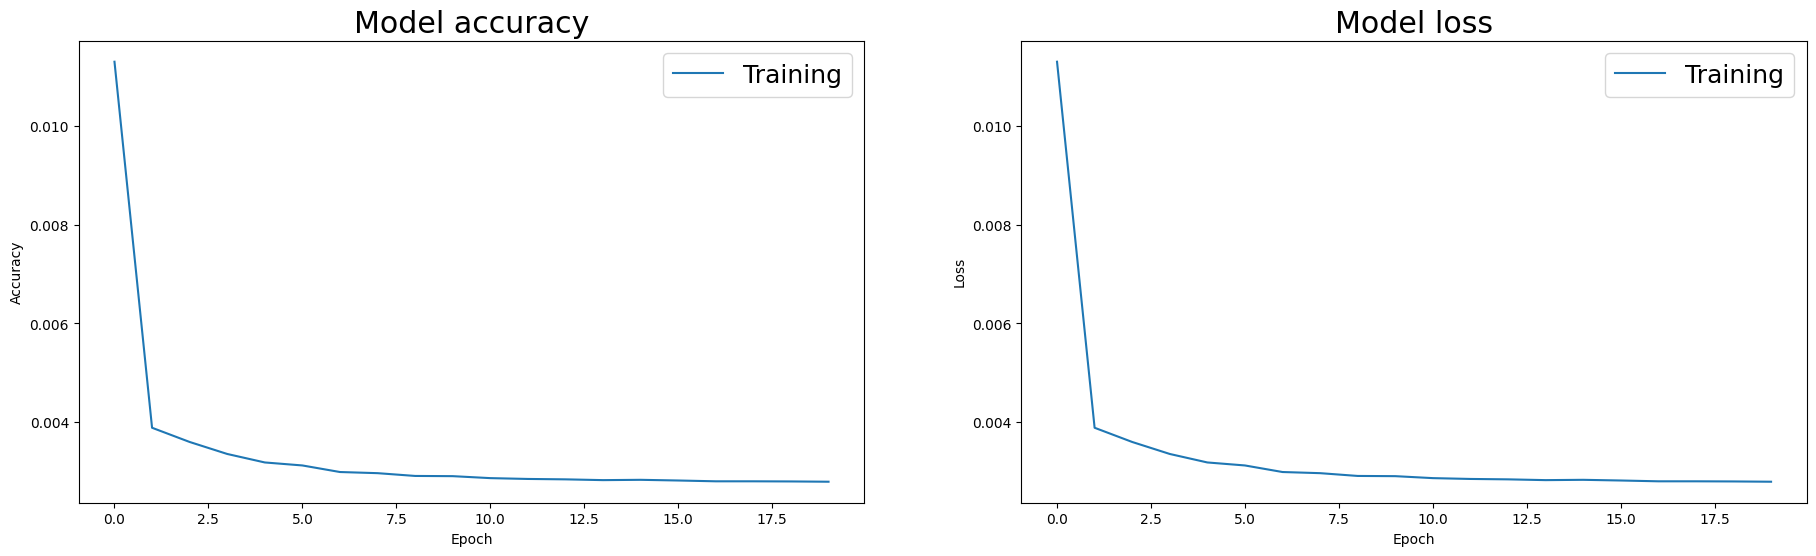

In [63]:
# Display learning curves
fig, ax = plt.subplots(1, 2, figsize = (18, 6))
fig.subplots_adjust(left = 0.02, right = 0.98, wspace = 0.2)

plt.rcParams.update({'font.size': 18})

# Plot training & validation accuracy values
ax[0].plot(history.history['mae'], label = 'Training')
# ax[0].plot(history.history['val_accuracy'], label = 'Validation')
ax[0].set_title('Model accuracy')
ax[0].set_ylabel('Accuracy')
ax[0].set_xlabel('Epoch')
ax[0].legend()

# Plot training & validation loss values
ax[1].plot(history.history['loss'], label = 'Training')
# ax[1].plot(history.history['val_loss'], label = 'Validation')
ax[1].set_title('Model loss')
ax[1].set_ylabel('Loss')
ax[1].set_xlabel('Epoch')
ax[1].legend()

plt.show()

In [64]:
# Multistep forecast for LSTM
def fcst_multisteps_ltsm(model, pred_iter, df, feat_scaler, tgt_scaler):
    # define min/max date for forecast horizon
    min_date = min(pred_iter) - pd.Timedelta(weeks=max_lags)
    max_date = max(pred_iter)

    # shallow copy
    pred_df = df.copy()
    # extracted data for required period
    df_fcst = pred_df[min_date:max_date]
    # drop lags which will not be used for LSTM
    df_fcst = df_fcst.drop(columns=["Weekly_Sales_lag1", "Weekly_Sales_lag2"])
    # MinMax scaling
    sc_col = ['Type', 'Size', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'year', 'quarter', 'month', 'week']
    df_fcst[sc_col] = feat_scaler.transform(df_fcst[sc_col])
    df_fcst[["Weekly_Sales"]] = tgt_scaler.transform(df_fcst[["Weekly_Sales"]])
    df_fcst_cols = df_fcst.columns.to_list() + ["Date"]

    for date in pred_iter:
        print("date=", date)
        min_date = date - pd.Timedelta(weeks=max_lags)
        # shallow copy
        slice_df = df_fcst.copy()
        # slice data for prediction
        slice_df = slice_df[min_date:date].reset_index()

        slice_df = slice_df.set_index("Date")

        time_steps = 2
        drop_cols = ["Store", "Dept"]
        # create data sequence for LSTM, output list will be used to store prediction values
        sequences, output_list = create_sequences(slice_df, time_steps, drop_cols)
        output_list = pd.DataFrame(output_list)

        # create data sequences
        X, y = zip(*sequences)
        X = np.array(X)
        y = np.array(y)

        # prediction
        y_pred_period = model.predict(X)

        # store prediction into sliced df
        output_list["Weekly_Sales_pred"] = y_pred_period
        output_list["Weekly_Sales_pred"]= output_list["Weekly_Sales_pred"].where(output_list["Weekly_Sales_pred"]>=0, 0)
        output_list_res = output_list[["Date", "Store", "Dept", "Weekly_Sales", "Weekly_Sales_pred"]]
        df_fcst = df_fcst.reset_index()

        # override weekly sales by prediction for next iteration
        df_fcst = pd.merge(df_fcst, output_list_res[["Date", "Store", "Dept", "Weekly_Sales_pred"]], on=["Date", "Store", "Dept"], how="left", suffixes=("", "_pred"))
        df_fcst["Weekly_Sales"] = df_fcst["Weekly_Sales_pred"].combine_first(df_fcst["Weekly_Sales"])
        df_fcst = df_fcst[df_fcst_cols]
        df_fcst = df_fcst.set_index("Date")

        # prepare output df
        output_list_res["Weekly_Sales"] = tgt_scaler.inverse_transform(output_list_res[["Weekly_Sales"]])
        output_list_res["Weekly_Sales_pred"] = tgt_scaler.inverse_transform(output_list_res[["Weekly_Sales_pred"]])
        output_list_res["gap"] = abs(output_list_res["Weekly_Sales"] - output_list_res["Weekly_Sales_pred"])
        output_list_res["Weekly_Sales"]= output_list_res["Weekly_Sales"].where(output_list_res["Weekly_Sales"]>=0, 0)

        # output df 
        if date == min(pred_iter):
            output = output_list_res.set_index("Date")
        else:
            output = pd.concat([output, output_list_res.set_index("Date")], axis=0)

    return output

In [65]:
# Multistep forecast
pred_start_date = "2012-10-05"
pred_end_date = pd.to_datetime(pred_start_date) + pd.Timedelta(weeks=3)
pred_iter = pd.date_range(pred_start_date, pred_end_date,freq="W-FRI")
print(pred_iter)

start_time = time.time()
output = fcst_multisteps_ltsm(model, pred_iter, df, scaler, scaler1)
output_all_pred_dict.update({"LSTM": output})
end_time = time.time()
print("Execution time: %s seconds" %(end_time - start_time))
print("------------")

DatetimeIndex(['2012-10-05', '2012-10-12', '2012-10-19', '2012-10-26'], dtype='datetime64[ns]', freq='W-FRI')
date= 2012-10-05 00:00:00
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
date= 2012-10-12 00:00:00
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 986us/step
date= 2012-10-19 00:00:00
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 996us/step
date= 2012-10-26 00:00:00
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 982us/step
Execution time: 3.17919921875 seconds
------------


In [66]:
# MAPE calculation for predictions
mape_df = output[output["Weekly_Sales"]>0]
overall_mape, mape_by_week = cal_mape(mape_df)  
print("overall MAPE =", overall_mape)
print(mape_by_week)

best_models["LSTM"].update({"test_score": overall_mape})

overall MAPE = 0.16633199739878263
            Store    Dept  Weekly_Sales  Weekly_Sales_pred           gap  \
Date                                                                       
2012-10-05  63020  125487   47521428.20         42817688.0  6.083817e+06   
2012-10-12  63007  125418   46078872.70         41254764.0  7.025933e+06   
2012-10-19  63065  125503   45073388.03         39536052.0  8.007644e+06   
2012-10-26  63013  125397   45480779.78         38569768.0  9.513386e+06   

                MAPE  
Date                  
2012-10-05  0.128023  
2012-10-12  0.152476  
2012-10-19  0.177658  
2012-10-26  0.209174  


# Model Selection

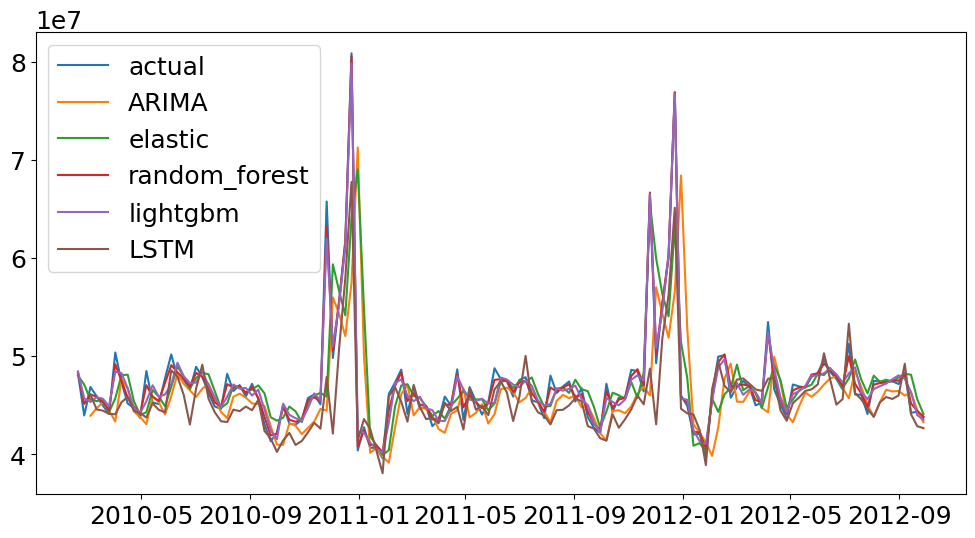

In [67]:
train_plot = y_train.groupby("Date").sum()
# pred_plot = y_pred_df.groupby("Date").sum()

plt.figure(figsize=(12,6))
plt.plot(train_plot.index, train_plot, label="actual")
for key, data in output_all_tr_dict.items():
    pred_plot = data.groupby("Date").sum()
    plt.plot(pred_plot.index, pred_plot["Weekly_Sales_pred"], label=f"{key}")
plt.legend()
plt.show()

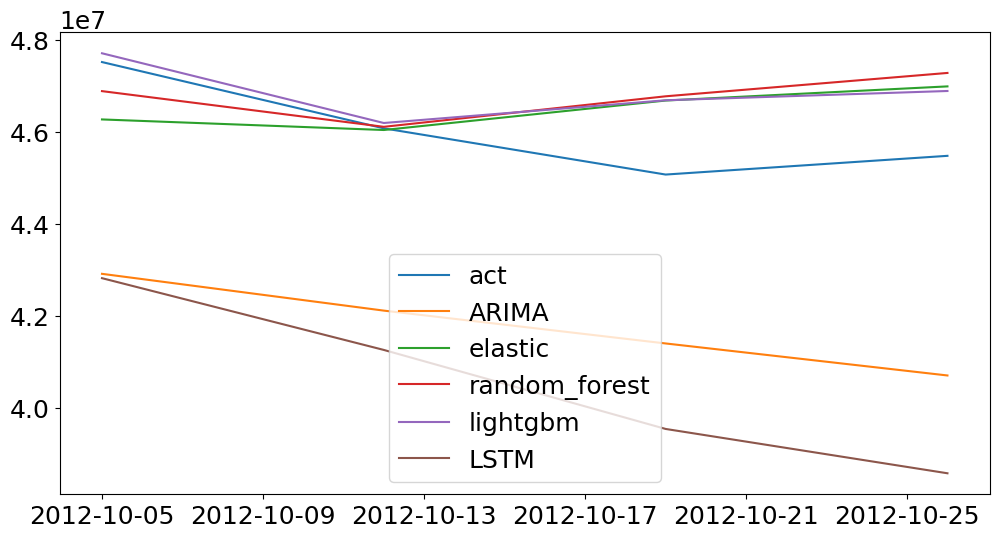

In [68]:
test_plot = y_test.groupby("Date").sum()
# pred_plot = output_all.groupby("Date")["Weekly_Sales_pred"].sum()

plt.figure(figsize=(12,6))
plt.plot(test_plot.index, test_plot, label="act")
for key, data in output_all_pred_dict.items():
    pred_plot = data.groupby("Date").sum()
    plt.plot(pred_plot.index, pred_plot["Weekly_Sales_pred"], label=f"{key}")
plt.legend()
plt.show()

In [69]:
best_models

{'elastic': {'estimator': ElasticNet(alpha=0.1),
  'params': {'alpha': 0.1},
  'train_score': 0.13460866984190528,
  'test_core': 0.1444108495216848},
 'random_forest': {'estimator': RandomForestRegressor(),
  'params': {'n_estimators': 100},
  'train_score': 0.038865171590184,
  'test_core': 0.10387134543296198},
 'lightgbm': {'estimator': LGBMRegressor(verbose=-1),
  'params': {'n_estimators': 100, 'verbose': -1},
  'train_score': 0.1004315428810325,
  'test_core': 0.10126139034155067},
 'LSTM': {'estimator': <Sequential name=sequential, built=True>,
  'params': {'epoch': 20, 'batch_size': 32},
  'train_score': 0.12151619899592747,
  'test_score': 0.16633199739878263}}

# Light GBM would be the best model  
1) Reliable accuracy (MAPE) ~ 1x%
2) Silimar accuracy on train/test data
3) Fast